In [8]:
%load_ext autoreload
%autoreload 2

# Compare 3T model with GaInP/GaAs r-type data
## Example MS874 from Geisz, et al., Cell Reports Physical Science 2, p. 100677 (2021) 

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pvcircuit.PlotWithControls import PlotsWithControls
import pvcircuit as pvc
import ipywidgets as widgets
#%matplotlib inline
#import ipympl
%matplotlib widget

#Operating system, 'glob' library - for getting list of files in directory
import os, glob



#Jupyter command for generating Matplotlib plots inline with the commands in the notebook
%matplotlib inline
#%matplotlib notebook

#import seaborn as sns
import scipy
import math
import re
import os


In [10]:
#set the working directory (where the data you want to work up is stored)
topwd='/Users/dcollins/Library/CloudStorage/OneDrive-NLR/3TT_diurnal_project/20250505'
os.chdir(topwd)
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*.mpt'))
filelist 

['MW114n1_CT_TRinCV_TZ_heldat0V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldat0V_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldat0mA_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldat0mA_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1V_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p25V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p25V_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p2V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p2V_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p3V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p3V_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p4V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatn1p4V_C02.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatnp1V_C01.mpt',
 'MW114n1_CT_TRinCV_TZ_heldatnp1V_C02.mpt',
 'MW114n1_CT_TZinCV_TR_heldat0mA_C01.mpt',
 'MW114n1_CT_TZinCV_TR_heldat0mA_C02.mpt',
 'MW114n1_CT_TZinCV_TR_heldat_0V_C01.mpt',
 'MW114n1_CT_TZinCV_TR_heldat_0V_C02.mpt',
 'MW114n1_CT_TZinCV_TR_heldat_0p1_short_C01.mpt',
 'MW114n1_CT_TZinCV_TR_heldat_0p1_short_C02.mpt',
 'MW114n1_CT_TZinCV_TR

In [11]:
#new attempt
A=1
Aratio=0.66
WB417n8dev3T = pvc.Tandem3T()


WB417n8dev3T.set(name='WB417n8dev3T', Rz = 2)
#WB417n8dev3T.top.?;;';et(Eg=1.42, n=[1, 2.23], J0ratio=[150, 2], Jext=0.0125, Gsh=1.5e-2,pn=1)
WB417n8dev3T.top.set(Eg=1.861, n=[1, 1], J0ratio=[20, 30], Jext=0.011, Gsh=3e-8,pn=1, Rser=0.005)
WB417n8dev3T.top.set( area=A, lightarea=0.98)
WB417n8dev3T.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}
#WB417n8dev3T.top.RBB_dict={'method':'pvmismatch','ARBD':arbd,'BRBD':brbd,'VRBD':vrb,'NRBD':nrbd}
#WB417n8dev3T.top.RBB_dict={'method':'bishop','mrb':3.2, 'avalanche':1, 'Vrb':-5.5}


#WB417n8dev3T.bot.set(Eg=1, n=[1, 3], J0ratio=[158, 20], Jext=0.006/Aratio, Gsh=3.89e-3, pn=-1)
WB417n8dev3T.bot.set(Eg=1.419, n=[1, 1], J0ratio=[20,25], Jext=0.0085, Gsh=7e-8, pn=-1, Rser=0.005)

WB417n8dev3T.bot.set( beta=4, area=A*Aratio, lightarea=0.65)
WB417n8dev3T.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}
#WB417n8dev3T.bot.RBB_dict={'method':'bishop','mrb':3.28, 'avalanche':1, 'Vrb':-5.5}

In [12]:
#single diode from dark
#new attempt
A=1
Aratio=0.66
WB417n8dev3T = pvc.Tandem3T()


WB417n8dev3T.set(name='WB417n8dev3T', Rz = 2,)
#WB417n8dev3T.top.?;;';et(Eg=1.42, n=[1, 2.23], J0ratio=[150, 2], Jext=0.0125, Gsh=1.5e-2,pn=1)
WB417n8dev3T.top.set(Eg=1.8, n=[3.25], J0ratio=[155], Jext=0.0111, Gsh=5e-4,pn=1, Rser=1.475)
WB417n8dev3T.top.set( area=A, lightarea=0.98)
#WB417n8dev3T.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}
#WB417n8dev3T.top.RBB_dict={'method':'pvmismatch','ARBD':arbd,'BRBD':brbd,'VRBD':vrb,'NRBD':nrbd}
#WB417n8dev3T.top.RBB_dict={'method':'bishop','mrb':3.2, 'avalanche':1, 'Vrb':-5.5}


#WB417n8dev3T.bot.set(Eg=1, n=[1, 3], J0ratio=[158, 20], Jext=0.006/Aratio, Gsh=3.89e-3, pn=-1)
WB417n8dev3T.bot.set(Eg=1.419, n=[2.3], J0ratio=[90], Jext=0.0095, Gsh=0.0055, pn=-1, Rser=1.2)

WB417n8dev3T.bot.set( beta=4, area=A*Aratio, lightarea=0.65)
#WB417n8dev3T.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}

In [13]:
#new two diode
#new attempt
A=1
Aratio=0.66
WB417n8dev3T = pvc.Tandem3T()


WB417n8dev3T.set(name='WB417n8dev3T', Rz = 2)
#WB417n8dev3T.top.?;;';et(Eg=1.42, n=[1, 2.23], J0ratio=[150, 2], Jext=0.0125, Gsh=1.5e-2,pn=1)
WB417n8dev3T.top.set(Eg=1.8, n=[1,2.3], J0ratio=[124,5570], Jext=0.007, Gsh=1e-7,pn=1, Rser=1.8)
WB417n8dev3T.top.set( area=A, lightarea=0.98)
#WB417n8dev3T.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}
#WB417n8dev3T.top.RBB_dict={'method':'pvmismatch','ARBD':arbd,'BRBD':brbd,'VRBD':vrb,'NRBD':nrbd}
#WB417n8dev3T.top.RBB_dict={'method':'bishop','mrb':3.2, 'avalanche':1, 'Vrb':-5.5}


#WB417n8dev3T.bot.set(Eg=1, n=[1, 3], J0ratio=[158, 20], Jext=0.006/Aratio, Gsh=3.89e-3, pn=-1)
WB417n8dev3T.bot.set(Eg=1.4, n=[1.8, 2.5], J0ratio=[10, 100], Jext=0.009, Gsh=0.005, pn=-1, Rser=1.2)

WB417n8dev3T.bot.set( beta=4, area=A*Aratio, lightarea=0.65)
#WB417n8dev3T.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}

In [14]:

A=1
Aratio=0.66
TTT1sun = pvc.Tandem3T()


TTT1sun.set(name='Model Fit', Rz = 2)
TTT1sun.top.set(Eg=1.861, n=[1, 3.4], J0ratio=[200, 270], Jext=0.0112, Gsh=3e-4,pn=1, Rser=1.5)
TTT1sun.top.set( area=A, lightarea=0.98)
TTT1sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}



TTT1sun.bot.set(Eg=1.419, n=[1, 4], J0ratio=[50,25], Jext=0.0085, Gsh=6e-3, pn=-1, Rser=0.001)

TTT1sun.bot.set( beta=15, area=A*Aratio, lightarea=0.65)
TTT1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}

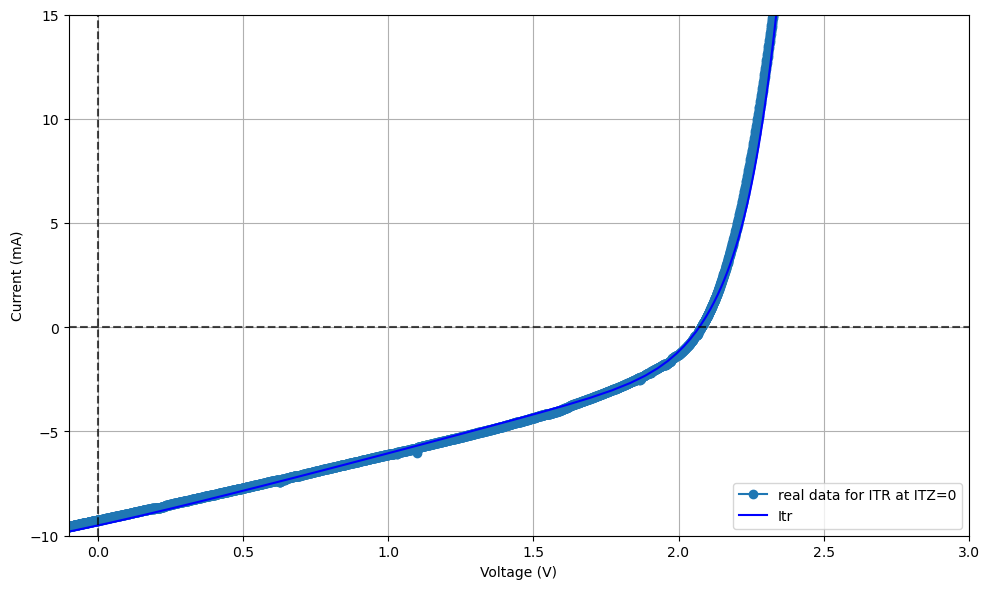

In [15]:
#model IV curve
tandem = TTT1sun 
iv_data = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data.area = tandem.lightarea
v_min = -0.015
v_max = 0.02
num_points = 100
iv_data.line(xkey="Iro", x0=v_min, x1=v_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem.V3T(iv_data)
#tandem.J3Tabs(iv_data)
#iv_data.kirchhoff(Iro,Izo)
#real data
os.chdir(topwd)
df = pd.read_csv('MW114n1_CT_TRinCV_TZ_heldat0mA_C01.mpt', skiprows= 62, encoding = "ISO-8859-1", delimiter='\t')
#'MW114n1_CT_TRinCV_TZ_heldatn1p2V_C01.mpt',
#'MW114n1_CT_TRinCV_TZ_heldat0mA_C01.mpt'
y=df['<I>/mA']
x=df['Ewe/V']

x = -x
y = -y
plt.figure(figsize=(10, 6))
plt.plot(x, y, marker='o', label='real data for ITR at ITZ=0')
plt.plot(1*iv_data.Vtr, (iv_data.Iro)*-1000, 'b-', label='Itr')
plt.xlim(-0.1,3)
plt.ylim(-10,15)
plt.xlabel('Voltage (V)')
plt.ylabel('Current (mA)')
plt.grid(True)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

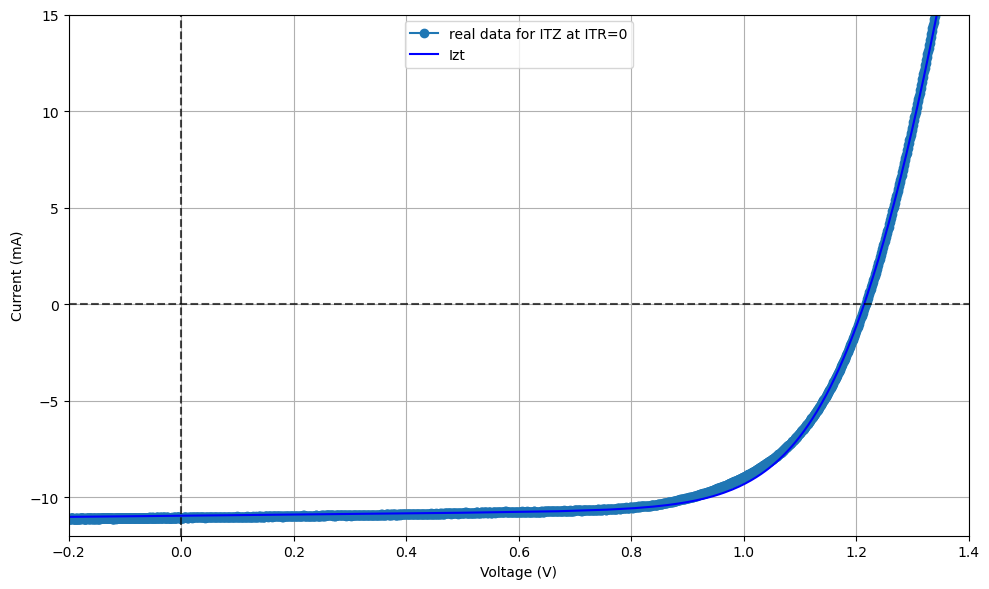

In [16]:
#model IV curve, TZ
tandem = TTT1sun 
iv_data_2 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_2.area = tandem.lightarea
i_min = -0.015
i_max = 0.025
num_points = 500
iv_data_2.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem.V3T(iv_data_2) 

os.chdir(topwd)
df = pd.read_csv('MW114n1_CT_TZinCV_TR_heldat0mA_C01.mpt', skiprows= 62, encoding = "ISO-8859-1", delimiter='\t')

y=df['<I>/mA']
x=df['Ewe/V']

x = -x
y = -y
plt.figure(figsize=(10, 6))
plt.plot(x, y, marker='o', label='real data for ITZ at ITR=0')
plt.plot(-iv_data_2.Vzt, (iv_data_2.Izo)*-1000, 'b-', label='Izt')
plt.xlabel('Voltage (V)')
plt.ylabel('Current (mA)')
plt.xlim(-0.2,1.4)
plt.grid(True)
plt.ylim(-12,15)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

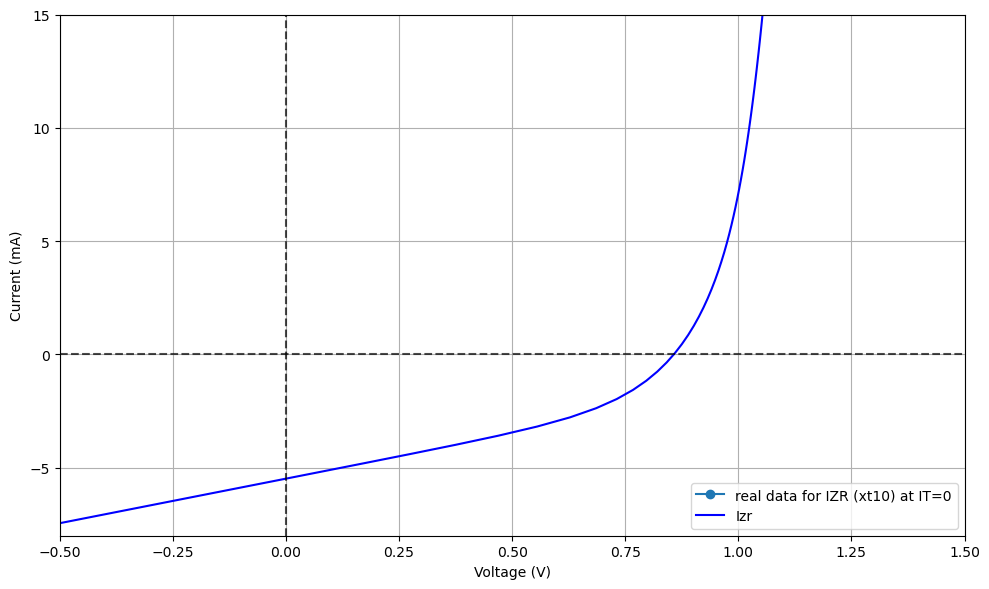

In [17]:

#model IV curve
tandem = TTT1sun
iv_data = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data.area = tandem.lightarea
v_min = -0.015
v_max = 0.025
num_points = 100
iv_data.line(xkey="Iro", x0=v_min, x1=v_max, xn=num_points, 
             ykey="Ito", yconstraint="0") 
tandem.V3T(iv_data)
#tandem.J3Tabs(iv_data)
#iv_data.kirchhoff(Iro,Izo)
#real data
os.chdir(topwd)
df = pd.read_csv('MW114n1_CT_TRinCV_TZ_heldat0mA_C01.mpt',  skiprows= 62, encoding = "ISO-8859-1", delimiter='\t')
#'MW114n1_CT_TRinCV_TZ_heldatn1p2V_C01.mpt',
#'MW114n1_CT_TRinCV_TZ_heldat0mA_C01.mpt'
x = df.iloc[:, 0]
y = df.iloc[:, 1]



plt.figure(figsize=(10, 6))
plt.plot(x, y, marker='o', label='real data for IZR (xt10) at IT=0')
plt.plot(-1*iv_data.Vrz, (iv_data.Iro)*-1000, 'b-', label='Izr')
plt.xlim(-0.5,1.5)
plt.ylim(-8,15)
plt.xlabel('Voltage (V)')
plt.ylabel('Current (mA)')
plt.grid(True)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
print(iv_data_2)

Vzt=0 IV Curve: <pvcircuit.iv3T.IV3T class>
{'name': 'Vzt=0 IV Curve', 'meastype': 'CT', 'area': 0.98, 'shape': (500,), 'xkey': 'Izo', 'ykey': 'Iro', 'x': (-0.015, 0.025), 'y': (0.0, 0.0)}
sizes(500, 500)

  #      mIro     mIzo     mIto     Vzt      Vrz      Vtr      mIA      mIB       VA       VB     mPtot    mIxhex   mIyhex   Vxhex    Vyhex  
 (0,)   0.00    -15.00    15.00   -1.343   -0.828    2.170    0.00    -15.00   -2.170   -1.343   -20.14   -10.61   -17.32   -2.484   -0.956  
 (1,)   0.00    -14.92    14.92   -1.342   -0.828    2.170    0.00    -14.92   -2.170   -1.342   -20.03   -10.55   -17.23   -2.484   -0.956  
 (2,)   0.00    -14.84    14.84   -1.342   -0.828    2.170    0.00    -14.84   -2.170   -1.342   -19.91   -10.49   -17.14   -2.483   -0.956  
 (3,)   0.00    -14.76    14.76   -1.341   -0.828    2.169    0.00    -14.76   -2.169   -1.341   -19.80   -10.44   -17.04   -2.482   -0.956  
 (4,)   0.00    -14.68    14.68   -1.341   -0.828    2.169    0.00    -14.68   -2.16

In [19]:
#0.5 sun
A=1
Aratio=0.66
p5sun = pvc.Tandem3T()


p5sun.set(name='p5sun', Rz = 2)
#WB417n8dev3T.top.?;;';et(Eg=1.42, n=[1, 2.23], J0ratio=[150, 2], Jext=0.0125, Gsh=1.5e-2,pn=1)
p5sun.top.set(Eg=1.861, n=[1, 1], J0ratio=[20, 30], Jext=0.0055, Gsh=3e-8,pn=1, Rser=0.0050)
p5sun.top.set( area=A, lightarea=0.98)
p5sun.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}
#WB417n8dev3T.top.RBB_dict={'method':'pvmismatch','ARBD':arbd,'BRBD':brbd,'VRBD':vrb,'NRBD':nrbd}
#WB417n8dev3T.top.RBB_dict={'method':'bishop','mrb':3.2, 'avalanche':1, 'Vrb':-5.5}


#WB417n8dev3T.bot.set(Eg=1, n=[1, 3], J0ratio=[158, 20], Jext=0.006/Aratio, Gsh=3.89e-3, pn=-1)
p5sun.bot.set(Eg=1.419, n=[1, 1], J0ratio=[20,25], Jext=0.0045, Gsh=7e-8, pn=-1, Rser=0.005)

p5sun.bot.set( beta=4, area=A*Aratio, lightarea=0.65)
p5sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':4e-4, 'Vrb':0.}
#WB417n8dev3T.bot.RBB_dict={'method':'bishop','mrb':3.28, 'avalanche':1, 'Vrb':-5.5}

In [20]:
#new attempt
A=1
Aratio=0.66
WB417n8dev3T = pvc.Tandem3T()


WB417n8dev3T.set(name='WB417n8dev3T', Rz = 2)
#WB417n8dev3T.top.?;;';et(Eg=1.42, n=[1, 2.23], J0ratio=[150, 2], Jext=0.0125, Gsh=1.5e-2,pn=1)
WB417n8dev3T.top.set(Eg=1.861, n=[1, 1], J0ratio=[80, 22], Jext=0.011, Gsh=1e-8,pn=1, Rser=1e-7)
WB417n8dev3T.top.set( area=A, lightarea=0.98)
WB417n8dev3T.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}
#WB417n8dev3T.top.RBB_dict={'method':'pvmismatch','ARBD':arbd,'BRBD':brbd,'VRBD':vrb,'NRBD':nrbd}
#WB417n8dev3T.top.RBB_dict={'method':'bishop','mrb':3.2, 'avalanche':1, 'Vrb':-5.5}


#WB417n8dev3T.bot.set(Eg=1, n=[1, 3], J0ratio=[158, 20], Jext=0.006/Aratio, Gsh=3.89e-3, pn=-1)
WB417n8dev3T.bot.set(Eg=1.419, n=[1, 1], J0ratio=[80,22], Jext=0.009, Gsh=5e-5, pn=-1, Rser=0.2)

WB417n8dev3T.bot.set( beta=4, area=A*Aratio, lightarea=0.65)
WB417n8dev3T.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':4e-4, 'Vrb':0.}
#WB417n8dev3T.bot.RBB_dict={'method':'bishop','mrb':3.28, 'avalanche':1, 'Vrb':-5.5}



In [21]:
#new attempt
from scipy.optimize import brentq
A=1
Aratio=0.66
p1sun = pvc.Tandem3T()


p1sun.set(name='p1sun', Rz = 2)
#WB417n8dev3T.top.?;;';et(Eg=1.42, n=[1, 2.23], J0ratio=[150, 2], Jext=0.0125, Gsh=1.5e-2,pn=1)
p1sun.top.set(Eg=1.87, n=[1, 1], J0ratio=[20, 30], Jext=0.0011, Gsh=3e-8,pn=1, Rser=0.1)
p1sun.top.set( area=A, lightarea=0.98)
p1sun.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}
#WB417n8dev3T.top.RBB_dict={'method':'pvmismatch','ARBD':arbd,'BRBD':brbd,'VRBD':vrb,'NRBD':nrbd}
#WB417n8dev3T.top.RBB_dict={'method':'bishop','mrb':3.2, 'avalanche':1, 'Vrb':-5.5}


#WB417n8dev3T.bot.set(Eg=1, n=[1, 3], J0ratio=[158, 20], Jext=0.006/Aratio, Gsh=3.89e-3, pn=-1)
p1sun.bot.set(Eg=1.419, n=[1, 1],J0ratio=[20,25], Jext=0.001, Gsh=7e-8, pn=-1, Rser=0.001)

p1sun.bot.set( beta=4, area=A*Aratio, lightarea=0.65)
p1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':4e-4, 'Vrb':0.}
#WB417n8dev3T.bot.RBB_dict={'method':'bishop','mrb':3.28, 'avalanche':1, 'Vrb':-5.5}

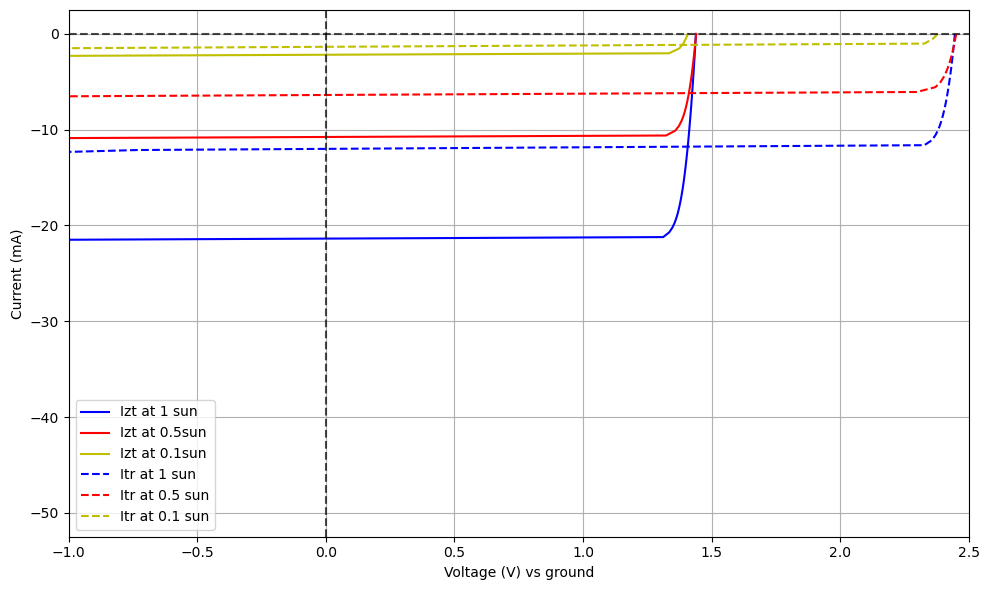

In [22]:
#Copper Catalyst COR
CuCORV = np.linspace(-0.8,2.5,500)
CuCORI = -2.81e-07 * np.exp(-(CuCORV+0.1)/.060)

#Gold Catalyst CO2 to CO
AuCO2RV = np.linspace(-0.4, 2.5, 500)
AuCO2RI = -7.41e-07 * np.exp(-(AuCO2RV+0.005)/.025)

#Copper Catalyst CO2R
CuCO2RV = np.linspace(-0.55, -1, 100)
CuCO2RI = -10**-7.1975 * np.exp(-(CuCO2RV + 0.2)/.060)



#model IV curve, TZ
tandem = WB417n8dev3T  
tandem_2 = p5sun
tandem_3 = p1sun




#TZ

iv_data_2 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_2.area = tandem.lightarea
iv_data_3 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_3.area = tandem_2.lightarea
iv_data_4 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_4.area = tandem_3.lightarea
i_min = 0
i_max = 0.025
num_points = 100
iv_data_2.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem.V3T(iv_data_2) 
iv_data_3.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_2.V3T(iv_data_3) 
iv_data_4.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_3.V3T(iv_data_4) 


#TR
iv_data_5 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_5.area = tandem.lightarea
iv_data_6 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_6.area = tandem_2.lightarea
iv_data_7 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_7.area = tandem_3.lightarea

df1 = [-0.55, -0.55378788, -0.55757576, -0.56136364, -0.56515152, -0.56893939,
 -0.57272727, -0.57651515, -0.58030303, -0.58409091, -0.58787879, -0.59166667,
 -0.59545455, -0.59924242, -0.6030303, -0.60681818, -0.61060606, -0.61439394,
 -0.61818182, -0.6219697, -0.62575758, -0.62954545, -0.63333333, -0.63712121,
 -0.64090909, -0.64469697, -0.64848485, -0.65227273, -0.65606061, -0.65984848,
 -0.66363636, -0.66742424, -0.67121212, -0.675, -0.67878788, -0.68257576,
 -0.68636364, -0.69015152, -0.69393939, -0.69772727, -0.70151515, -0.70530303,
 -0.70909091, -0.71287879, -0.71666667, -0.72045455, -0.72424242, -0.7280303,
 -0.73181818, -0.73560606, -0.73939394, -0.74318182, -0.7469697, -0.75075758,
 -0.75454545, -0.75833333, -0.76212121, -0.76590909, -0.76969697, -0.77348485,
 -0.77727273, -0.78106061, -0.78484848, -0.78863636, -0.79242424, -0.79621212,
 -0.8, -0.80378788, -0.80757576, -0.81136364, -0.81515152, -0.81893939,
 -0.82272727, -0.82651515, -0.83030303, -0.83409091, -0.83787879, -0.84166667,
 -0.84545455, -0.84924242, -0.8530303, -0.85681818, -0.86060606, -0.86439394,
 -0.86818182, -0.8719697, -0.87575758, -0.87954545, -0.88333333, -0.88712121,
 -0.89090909, -0.89469697, -0.89848485, -0.90227273, -0.90606061, -0.90984848,
 -0.91363636, -0.91742424, -0.92121212, -0.925]

i_min = 0
i_max = 0.025
num_points = 100
iv_data_5.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem.V3T(iv_data_5)
iv_data_6.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem_2.V3T(iv_data_6)
iv_data_7.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0")  
tandem_3.V3T(iv_data_7)

plt.figure(figsize=(10, 6))
#plt.plot(x, y, marker='o', label='real data for ITZ at ITR=0')
plt.plot(-iv_data_2.Vzt, (iv_data_2.Ito-iv_data_2.Izo)*1000, 'b-', label='Izt at 1 sun')
plt.plot(-iv_data_3.Vzt, (iv_data_3.Ito-iv_data_3.Izo)*1000, 'r-', label='Izt at 0.5sun')
plt.plot(-iv_data_4.Vzt, (iv_data_4.Ito-iv_data_4.Izo)*1000, 'y-', label='Izt at 0.1sun')
plt.plot(iv_data_5.Vtr, (iv_data_5.Ito-iv_data_5.Iro)*1000, 'b--', label='Itr at 1 sun')
plt.plot(iv_data_6.Vtr, (iv_data_6.Ito-iv_data_6.Iro)*1000, 'r--', label='Itr at 0.5 sun')
plt.plot(iv_data_7.Vtr, (iv_data_7.Ito-iv_data_7.Iro)*1000, 'y--', label='Itr at 0.1 sun')
#plt.plot(AuCO2RV, AuCO2RI * 1000, color = 'tab:pink', linestyle = '-', label = 'Au CO$_2$R')
#plt.plot(CuCO2RV, CuCO2RI * 1000, 'k-', label = 'Cu CO$_2$R')
#plt.plot(CuCORV, CuCORI * 1000, 'g-', label = 'Cu COR')
plt.xlabel('Voltage (V) vs ground')
plt.ylabel('Current (mA)')
plt.xlim(-1.0,2.5)
#plt.ylim(-25,5)
plt.grid(True)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

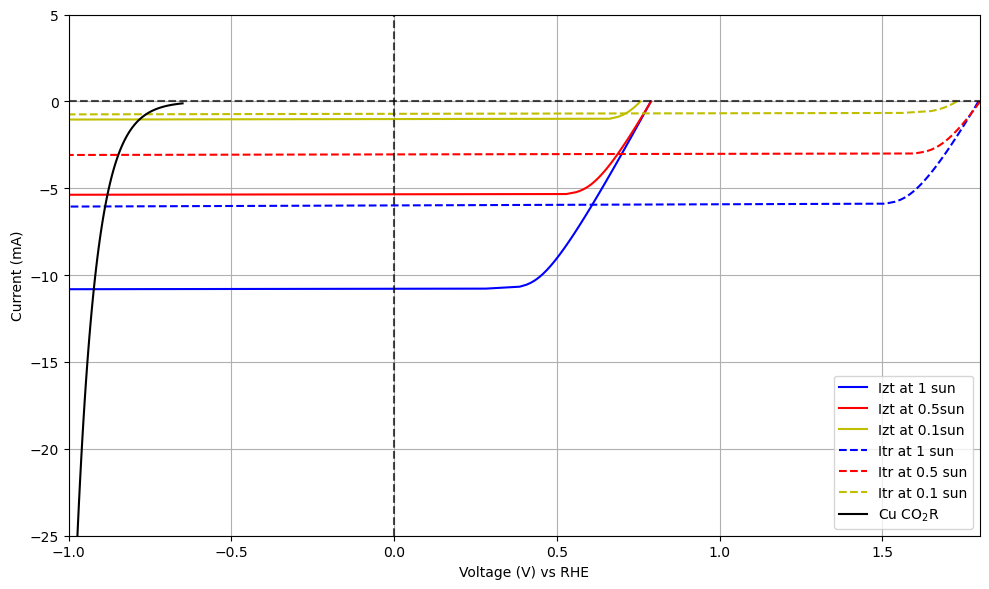

In [23]:
#Copper Catalyst COR
CuCORV = np.linspace(-0.45,2.5,500)
CuCORI = -2.81e-07 * np.exp(-(CuCORV+0.1)/.060)

#Gold Catalyst CO2 to CO
AuCO2RV = np.linspace(-.15, 2.5, 500)
AuCO2RI = -7.41e-07 * np.exp(-(AuCO2RV+0.005)/.025)

#Copper Catalyst CO2R
CuCO2RV = np.linspace(-0.65, -1, 100)
CuCO2RI = -10**-7.1975 * np.exp(-(CuCO2RV + 0.2)/.060)



#model IV curve, TZ
tandem = WB417n8dev3T  
tandem_2 = p5sun
tandem_3 = p1sun




#TZ

iv_data_2 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_2.area = tandem.lightarea
iv_data_3 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_3.area = tandem_2.lightarea
iv_data_4 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_4.area = tandem_3.lightarea
i_min = 0
i_max = 0.011
num_points = 100
iv_data_2.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem.V3T(iv_data_2) 
iv_data_3.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_2.V3T(iv_data_3) 
iv_data_4.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_3.V3T(iv_data_4) 


#TR
iv_data_5 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_5.area = tandem.lightarea
iv_data_6 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_6.area = tandem_2.lightarea
iv_data_7 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_7.area = tandem_3.lightarea

df1 = [-0.65, -0.65275758, -0.65551515, -0.65827273, -0.6610303, -0.66378788,
 -0.66654545, -0.66930303, -0.67206061, -0.67481818, -0.67757576, -0.68033333,
 -0.68309091, -0.68584848, -0.68860606, -0.69136364, -0.69412121, -0.69687879,
 -0.69963636, -0.70239394, -0.70515152, -0.70790909, -0.71066667, -0.71342424,
 -0.71618182, -0.71893939, -0.72169697, -0.72445455, -0.72721212, -0.7299697,
 -0.73272727, -0.73548485, -0.73824242, -0.741, -0.74375758, -0.74651515,
 -0.74927273, -0.7520303, -0.75478788, -0.75754545, -0.76030303, -0.76306061,
 -0.76581818, -0.76857576, -0.77133333, -0.77409091, -0.77684848, -0.77960606,
 -0.78236364, -0.78512121, -0.78787879, -0.79063636, -0.79339394, -0.79615152,
 -0.79890909, -0.80166667, -0.80442424, -0.80718182, -0.80993939, -0.81269697,
 -0.81545455, -0.81821212, -0.8209697, -0.82372727, -0.82648485, -0.82924242,
 -0.832, -0.83475758, -0.83751515, -0.84027273, -0.8430303, -0.84578788,
 -0.84854545, -0.85130303, -0.85406061, -0.85681818, -0.85957576, -0.86233333,
 -0.86509091, -0.86784848, -0.87060606, -0.87336364, -0.87612121, -0.87887879,
 -0.88163636, -0.88439394, -0.88715152, -0.88990909, -0.89266667, -0.89542424,
 -0.89818182, -0.90093939, -0.90369697, -0.90645455, -0.90921212, -0.9119697,
 -0.91472727, -0.91748485, -0.92024242, -0.923]

i_min = 0
i_max = 0.011
num_points = 100
iv_data_5.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem.V3T(iv_data_5)
iv_data_6.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem_2.V3T(iv_data_6)
iv_data_7.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0")  
tandem_3.V3T(iv_data_7)

plt.figure(figsize=(10, 6))
#plt.plot(x, y, marker='o', label='real data for ITZ at ITR=0')
plt.plot(df1-iv_data_2.Vzt, (iv_data_2.Izo)*-1000, 'b-', label='Izt at 1 sun')
plt.plot(df1-iv_data_3.Vzt, (iv_data_3.Izo)*-1000, 'r-', label='Izt at 0.5sun')
plt.plot(df1-iv_data_4.Vzt, (iv_data_4.Izo)*-1000, 'y-', label='Izt at 0.1sun')
plt.plot(df1+iv_data_5.Vtr, (iv_data_5.Iro)*-1000, 'b--', label='Itr at 1 sun')
plt.plot(df1+iv_data_6.Vtr, (iv_data_6.Iro)*-1000, 'r--', label='Itr at 0.5 sun')
plt.plot(df1+iv_data_7.Vtr, (iv_data_7.Iro)*-1000, 'y--', label='Itr at 0.1 sun')
#plt.plot(AuCO2RV, AuCO2RI * 1000, color = 'tab:pink', linestyle = '-', label = 'Au CO$_2$R')
plt.plot(CuCO2RV, CuCO2RI * 1000, 'k-', label = 'Cu CO$_2$R')
#plt.plot(CuCORV, CuCORI * 1000, 'g-', label = 'Cu COR')
plt.xlabel('Voltage (V) vs RHE')
plt.ylabel('Current (mA)')
plt.xlim(-1.0,1.8)
plt.ylim(-25,5)
plt.grid(True)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

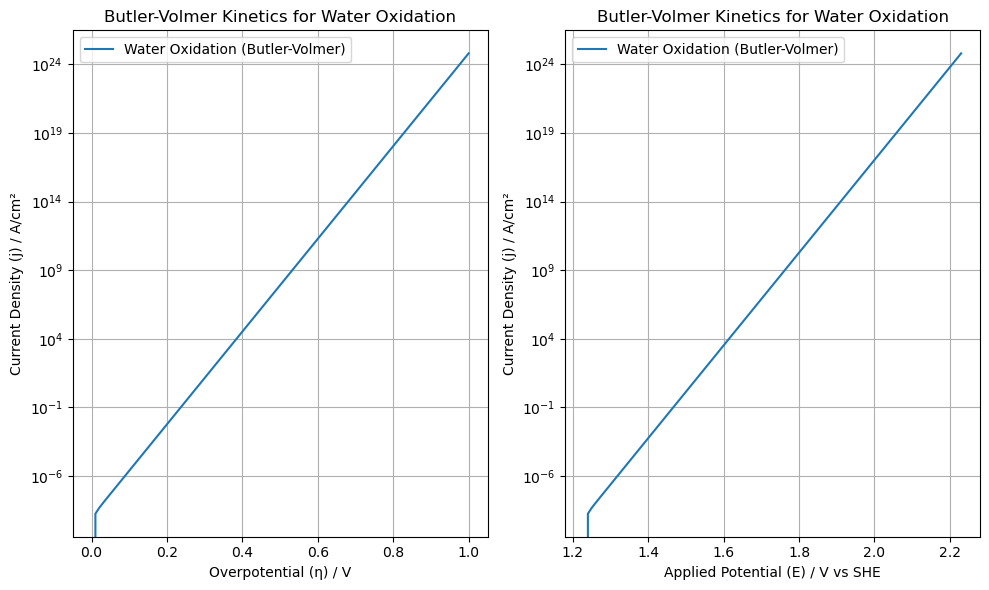

Equilibrium potential (E_eq): 1.23 V
Exchange current density (j0): 1e-09 A/cm^2
Charge transfer coefficient (alpha): 0.5
Number of electrons (n): 4
Temperature (T): 298.15 K


In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
F = 96485  # Faraday's constant (C/mol)
R = 8.314  # Ideal gas constant (J/(mol·K))
T = 298.15 # Temperature (K) - 25°C
n = 4      # Number of electrons transferred for water oxidation

# Parameters for Water Oxidation (example values)
j0 = 1e-9  # Exchange current density (A/cm^2) - highly variable
alpha = 0.5 # Charge transfer coefficient (dimensionless)
E_eq = 1.23 # Equilibrium potential for OER (V vs SHE, standard conditions)

# Overpotential range for oxidation (anodic process)
# We typically look at positive overpotentials for oxidation
overpotential = np.linspace(0, 1.0, 100) # From 0 V to 1.0 V

# Calculate current density using Butler-Volmer equation
# For oxidation, we mainly focus on the anodic term,
# but the full Butler-Volmer accounts for both.
# The term (1-alpha) for the anodic reaction in the common form
# refers to alpha being the cathodic transfer coefficient.
# If alpha is the anodic transfer coefficient, then the equation
# for the anodic current (j_a) would be j_a = j0 * exp(alpha * n * F * eta / (R * T))
# and for cathodic (j_c) would be j_c = -j0 * exp(-(1-alpha) * n * F * eta / (R * T)).
# The commonly written Butler-Volmer equation combines these terms.
# So, for an anodic reaction, we expect a positive current.

# The general Butler-Volmer equation: j = j_0 [exp((1-alpha)*nF*eta/(RT)) - exp(-alpha*nF*eta/(RT))]
# Here, 'alpha' is often referred to as the cathodic transfer coefficient.
# For a pure oxidation reaction, and if alpha represents the anodic transfer coefficient,
# you might see simplified forms. Let's stick to the common form where
# alpha is the transfer coefficient for the cathodic reaction (reduction),
# so (1-alpha) is for the anodic reaction (oxidation).

j_anodic = j0 * np.exp((1 - alpha) * n * F * overpotential / (R * T))
j_cathodic = j0 * np.exp(-alpha * n * F * overpotential / (R * T)) # Note: this term would be negative for actual cathodic currents

# Net current density
current_density = j_anodic - j_cathodic

# Calculate applied potential
applied_potential = E_eq + overpotential

# Plotting
plt.figure(figsize=(10, 6))

# Plotting current density vs. overpotential
plt.subplot(1, 2, 1)
plt.plot(overpotential, current_density, label='Water Oxidation (Butler-Volmer)')
plt.xlabel('Overpotential (η) / V')
plt.ylabel('Current Density (j) / A/cm²')
plt.title('Butler-Volmer Kinetics for Water Oxidation')
plt.grid(True)
plt.yscale('log') # Use log scale for current density due to exponential nature
plt.legend()

# Plotting current density vs. applied potential
plt.subplot(1, 2, 2)
plt.plot(applied_potential, current_density, label='Water Oxidation (Butler-Volmer)')
plt.xlabel('Applied Potential (E) / V vs SHE')
plt.ylabel('Current Density (j) / A/cm²')
plt.title('Butler-Volmer Kinetics for Water Oxidation')
plt.grid(True)
plt.yscale('log') # Use log scale for current density
plt.legend()

plt.tight_layout()
plt.show()

print(f"Equilibrium potential (E_eq): {E_eq} V")
print(f"Exchange current density (j0): {j0} A/cm^2")
print(f"Charge transfer coefficient (alpha): {alpha}")
print(f"Number of electrons (n): {n}")
print(f"Temperature (T): {T} K")

In [25]:
print(CuCO2RV)

[-0.65       -0.65353535 -0.65707071 -0.66060606 -0.66414141 -0.66767677
 -0.67121212 -0.67474747 -0.67828283 -0.68181818 -0.68535354 -0.68888889
 -0.69242424 -0.6959596  -0.69949495 -0.7030303  -0.70656566 -0.71010101
 -0.71363636 -0.71717172 -0.72070707 -0.72424242 -0.72777778 -0.73131313
 -0.73484848 -0.73838384 -0.74191919 -0.74545455 -0.7489899  -0.75252525
 -0.75606061 -0.75959596 -0.76313131 -0.76666667 -0.77020202 -0.77373737
 -0.77727273 -0.78080808 -0.78434343 -0.78787879 -0.79141414 -0.79494949
 -0.79848485 -0.8020202  -0.80555556 -0.80909091 -0.81262626 -0.81616162
 -0.81969697 -0.82323232 -0.82676768 -0.83030303 -0.83383838 -0.83737374
 -0.84090909 -0.84444444 -0.8479798  -0.85151515 -0.85505051 -0.85858586
 -0.86212121 -0.86565657 -0.86919192 -0.87272727 -0.87626263 -0.87979798
 -0.88333333 -0.88686869 -0.89040404 -0.89393939 -0.89747475 -0.9010101
 -0.90454545 -0.90808081 -0.91161616 -0.91515152 -0.91868687 -0.92222222
 -0.92575758 -0.92929293 -0.93282828 -0.93636364 -0.

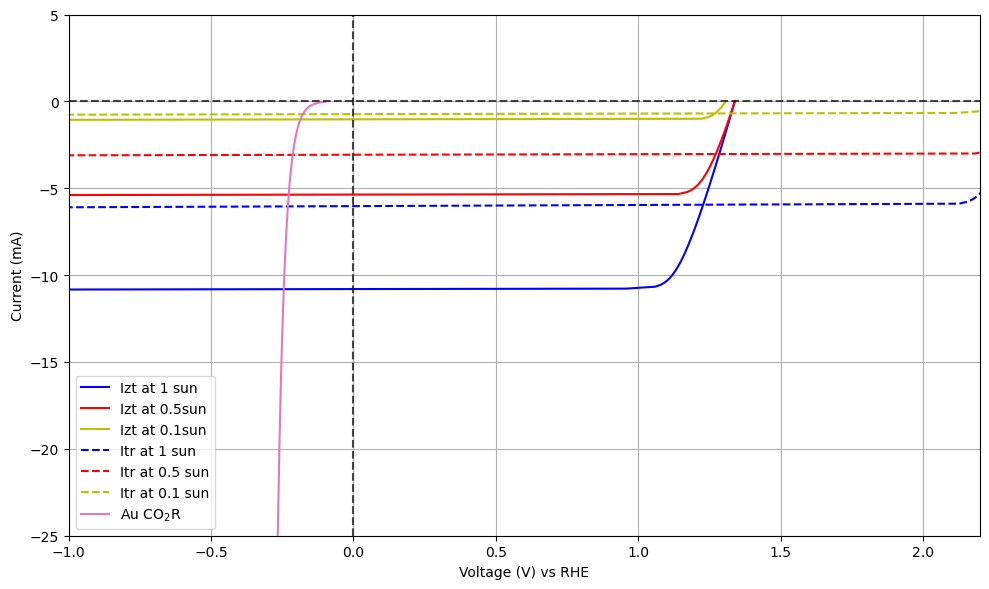

In [26]:
#Copper Catalyst COR
CuCORV = np.linspace(-0.8,2.5,500)
CuCORI = -2.81e-07 * np.exp(-(CuCORV+0.1)/.060)

#Gold Catalyst CO2 to CO
AuCO2RV = np.linspace(-0.1, -.3, 100)
AuCO2RI = -7.41e-07 * np.exp(-(AuCO2RV+0.005)/.025)

#Copper Catalyst CO2R
CuCO2RV = np.linspace(-0.55, -1, 100)
CuCO2RI = -10**-7.1975 * np.exp(-(CuCO2RV + 0.2)/.060)



#model IV curve, TZ
tandem = WB417n8dev3T  
tandem_2 = p5sun
tandem_3 = p1sun




#TZ

iv_data_2 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_2.area = tandem.lightarea
iv_data_3 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_3.area = tandem_2.lightarea
iv_data_4 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_4.area = tandem_3.lightarea
i_min = 0
i_max = 0.011
num_points = 100
iv_data_2.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem.V3T(iv_data_2) 
iv_data_3.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_2.V3T(iv_data_3) 
iv_data_4.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_3.V3T(iv_data_4) 


#TR
iv_data_5 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_5.area = tandem.lightarea
iv_data_6 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_6.area = tandem_2.lightarea
iv_data_7 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_7.area = tandem_3.lightarea

df1 = [-0.1, -0.10146465, -0.10292929, -0.10439394, -0.10585859, -0.10732323,
 -0.10878788, -0.11025253, -0.11171717, -0.11318182, -0.11464646, -0.11611111,
 -0.11757576, -0.1190404, -0.12050505, -0.1219697, -0.12343434, -0.12489899,
 -0.12636364, -0.12782828, -0.12929293, -0.13075758, -0.13222222, -0.13368687,
 -0.13515152, -0.13661616, -0.13808081, -0.13954545, -0.1410101, -0.14247475,
 -0.14393939, -0.14540404, -0.14686869, -0.14833333, -0.14979798, -0.15126263,
 -0.15272727, -0.15419192, -0.15565657, -0.15712121, -0.15858586, -0.16005051,
 -0.16151515, -0.1629798, -0.16444444, -0.16590909, -0.16737374, -0.16883838,
 -0.17030303, -0.17176768, -0.17323232, -0.17469697, -0.17616162, -0.17762626,
 -0.17909091, -0.18055556, -0.1820202, -0.18348485, -0.18494949, -0.18641414,
 -0.18787879, -0.18934343, -0.19080808, -0.19227273, -0.19373737, -0.19520202,
 -0.19666667, -0.19813131, -0.19959596, -0.20106061, -0.20252525, -0.2039899,
 -0.20545455, -0.20691919, -0.20838384, -0.20984848, -0.21131313, -0.21277778,
 -0.21424242, -0.21570707, -0.21717172, -0.21863636, -0.22010101, -0.22156566,
 -0.2230303, -0.22449495, -0.2259596, -0.22742424, -0.22888889, -0.23035354,
 -0.23181818, -0.23328283, -0.23474747, -0.23621212, -0.23767677, -0.23914141,
 -0.24060606, -0.24207071, -0.24353535, -0.245]

i_min = 0
i_max = 0.011
num_points = 100
iv_data_5.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem.V3T(iv_data_5)
iv_data_6.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem_2.V3T(iv_data_6)
iv_data_7.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0")  
tandem_3.V3T(iv_data_7)

plt.figure(figsize=(10, 6))
#plt.plot(x, y, marker='o', label='real data for ITZ at ITR=0')
plt.plot(df1-iv_data_2.Vzt, (iv_data_2.Izo)*-1000, 'b-', label='Izt at 1 sun')
plt.plot(df1-iv_data_3.Vzt, (iv_data_3.Izo)*-1000, 'r-', label='Izt at 0.5sun')
plt.plot(df1-iv_data_4.Vzt, (iv_data_4.Izo)*-1000, 'y-', label='Izt at 0.1sun')
plt.plot(df1+iv_data_5.Vtr, (iv_data_5.Iro)*-1000, 'b--', label='Itr at 1 sun')
plt.plot(df1+iv_data_6.Vtr, (iv_data_6.Iro)*-1000, 'r--', label='Itr at 0.5 sun')
plt.plot(df1+iv_data_7.Vtr, (iv_data_7.Iro)*-1000, 'y--', label='Itr at 0.1 sun')
plt.plot(AuCO2RV, AuCO2RI * 1000, color = 'tab:pink', linestyle = '-', label = 'Au CO$_2$R')
#plt.plot(CuCO2RV, CuCO2RI * 1000, 'k-', label = 'Cu CO$_2$R')
#plt.plot(CuCORV, CuCORI * 1000, 'g-', label = 'Cu COR')
plt.xlabel('Voltage (V) vs RHE')
plt.ylabel('Current (mA)')
plt.xlim(-1.0,2.2)
plt.ylim(-25,5)
plt.grid(True)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

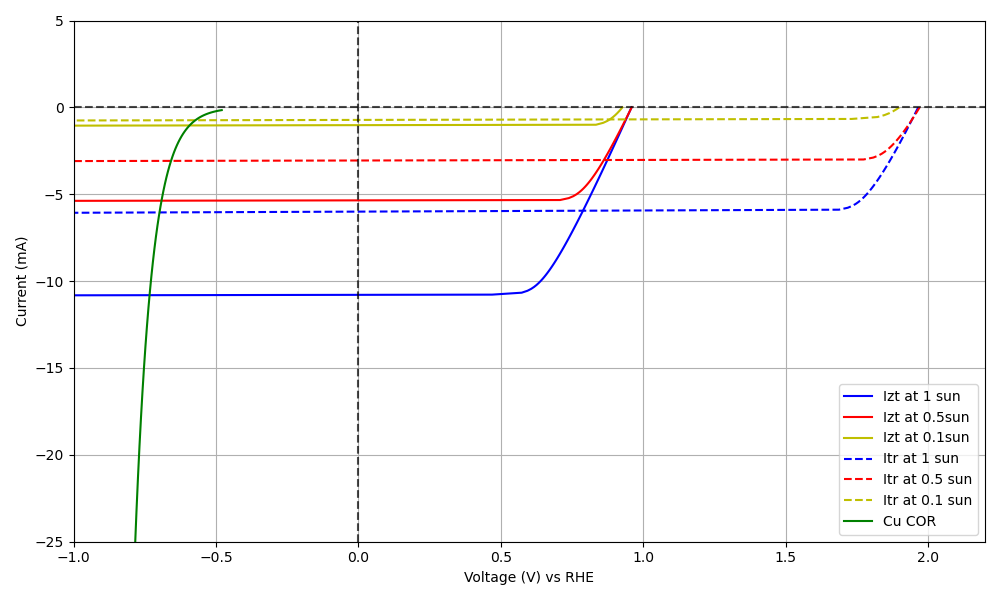

In [27]:
%matplotlib inline
#%matplotlib notebook
%matplotlib widget
#Copper Catalyst COR
CuCORV = np.linspace(-0.48,-1,100)
CuCORI = -2.81e-07 * np.exp(-(CuCORV+0.1)/.060)

#Gold Catalyst CO2 to CO
AuCO2RV = np.linspace(-0.1, -.3, 100)
AuCO2RI = -7.41e-07 * np.exp(-(AuCO2RV+0.005)/.025)

#Copper Catalyst CO2R
CuCO2RV = np.linspace(-0.55, -1, 100)
CuCO2RI = -10**-7.1975 * np.exp(-(CuCO2RV + 0.2)/.060)



#model IV curve, TZ
tandem = WB417n8dev3T  
tandem_2 = p5sun
tandem_3 = p1sun




#TZ

iv_data_2 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_2.area = tandem.lightarea
iv_data_3 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_3.area = tandem_2.lightarea
iv_data_4 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_4.area = tandem_3.lightarea
i_min = 0
i_max = 0.011
num_points = 100
iv_data_2.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem.V3T(iv_data_2) 
iv_data_3.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_2.V3T(iv_data_3) 
iv_data_4.line(xkey="Izo", x0=i_min, x1=i_max, xn=num_points, ykey="Iro", yconstraint="0")  
tandem_3.V3T(iv_data_4) 


#TR
iv_data_5 = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data_5.area = tandem.lightarea
iv_data_6 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_6.area = tandem_2.lightarea
iv_data_7 = pvc.IV3T(name="Vzt=-1 IV Curve", meastype="CT")
iv_data_7.area = tandem_3.lightarea

df1 = [-0.48, -0.48257576, -0.48515152, -0.48772727, -0.49030303, -0.49287879,
 -0.49545455, -0.4980303, -0.50060606, -0.50318182, -0.50575758, -0.50833333,
 -0.51090909, -0.51348485, -0.51606061, -0.51863636, -0.52121212, -0.52378788,
 -0.52636364, -0.52893939, -0.53151515, -0.53409091, -0.53666667, -0.53924242,
 -0.54181818, -0.54439394, -0.5469697, -0.54954545, -0.55212121, -0.55469697,
 -0.55727273, -0.55984848, -0.56242424, -0.565, -0.56757576, -0.57015152,
 -0.57272727, -0.57530303, -0.57787879, -0.58045455, -0.5830303, -0.58560606,
 -0.58818182, -0.59075758, -0.59333333, -0.59590909, -0.59848485, -0.60106061,
 -0.60363636, -0.60621212, -0.60878788, -0.61136364, -0.61393939, -0.61651515,
 -0.61909091, -0.62166667, -0.62424242, -0.62681818, -0.62939394, -0.6319697,
 -0.63454545, -0.63712121, -0.63969697, -0.64227273, -0.64484848, -0.64742424,
 -0.65, -0.65257576, -0.65515152, -0.65772727, -0.66030303, -0.66287879,
 -0.66545455, -0.6680303, -0.67060606, -0.67318182, -0.67575758, -0.67833333,
 -0.68090909, -0.68348485, -0.68606061, -0.68863636, -0.69121212, -0.69378788,
 -0.69636364, -0.69893939, -0.70151515, -0.70409091, -0.70666667, -0.70924242,
 -0.71181818, -0.71439394, -0.7169697, -0.71954545, -0.72212121, -0.72469697,
 -0.72727273, -0.72984848, -0.73242424, -0.735]

i_min = 0
i_max = 0.011
num_points = 100
iv_data_5.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem.V3T(iv_data_5)
iv_data_6.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0") 
tandem_2.V3T(iv_data_6)
iv_data_7.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points, 
             ykey="Izo", yconstraint="0")  
tandem_3.V3T(iv_data_7)

plt.figure(figsize=(10, 6))
#plt.plot(x, y, marker='o', label='real data for ITZ at ITR=0')
plt.plot(df1-iv_data_2.Vzt, (iv_data_2.Izo)*-1000, 'b-', label='Izt at 1 sun')
plt.plot(df1-iv_data_3.Vzt, (iv_data_3.Izo)*-1000, 'r-', label='Izt at 0.5sun')
plt.plot(df1-iv_data_4.Vzt, (iv_data_4.Izo)*-1000, 'y-', label='Izt at 0.1sun')
plt.plot(df1+iv_data_5.Vtr, (iv_data_5.Iro)*-1000, 'b--', label='Itr at 1 sun')
plt.plot(df1+iv_data_6.Vtr, (iv_data_6.Iro)*-1000, 'r--', label='Itr at 0.5 sun')
plt.plot(df1+iv_data_7.Vtr, (iv_data_7.Iro)*-1000, 'y--', label='Itr at 0.1 sun')
#plt.plot(AuCO2RV, AuCO2RI * 1000, color = 'tab:pink', linestyle = '-', label = 'Au CO$_2$R')
#plt.plot(CuCO2RV, CuCO2RI * 1000, 'k-', label = 'Cu CO$_2$R')
plt.plot(CuCORV, CuCORI * 1000, 'g-', label = 'Cu COR')
plt.xlabel('Voltage (V) vs RHE')
plt.ylabel('Current (mA)')
plt.xlim(-1.0,2.2)
plt.ylim(-25,5)
plt.grid(True)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
print(find_zero_crossing(CuCORV,CuCORI))
print(CuCORV, CuCORI * 1000)
print((iv_data_2.Izo)*-1000)
print(-iv_data_2.Vzt)

NameError: name 'find_zero_crossing' is not defined

In [29]:
print(CuCO2RV)
# Function to find x-axis crossing (where y=0)
def find_zero_crossing(voltage, current):
    """
    Find the voltage where current crosses zero (y=0)
    """
    try:
        from scipy.interpolate import interp1d
        # Create interpolation function
        interp_func = interp1d(current, voltage, bounds_error=False, fill_value='extrapolate')
        # Find voltage at current = 0
        zero_crossing = float(interp_func(0))
        return zero_crossing
    except:
        # Fallback: find closest point to zero
        zero_idx = np.argmin(np.abs(current))
        return float(voltage[zero_idx])
print(find_zero_crossing(-iv_data_2.Vzt, (iv_data_2.Izo)*-1000))

print(find_zero_crossing(CuCO2RV,CuCO2RI))
print(CuCO2RV, CuCO2RI * 1000)
print((iv_data_2.Izo)*-1000)
print(-iv_data_2.Vzt)

[-0.55       -0.55454545 -0.55909091 -0.56363636 -0.56818182 -0.57272727
 -0.57727273 -0.58181818 -0.58636364 -0.59090909 -0.59545455 -0.6
 -0.60454545 -0.60909091 -0.61363636 -0.61818182 -0.62272727 -0.62727273
 -0.63181818 -0.63636364 -0.64090909 -0.64545455 -0.65       -0.65454545
 -0.65909091 -0.66363636 -0.66818182 -0.67272727 -0.67727273 -0.68181818
 -0.68636364 -0.69090909 -0.69545455 -0.7        -0.70454545 -0.70909091
 -0.71363636 -0.71818182 -0.72272727 -0.72727273 -0.73181818 -0.73636364
 -0.74090909 -0.74545455 -0.75       -0.75454545 -0.75909091 -0.76363636
 -0.76818182 -0.77272727 -0.77727273 -0.78181818 -0.78636364 -0.79090909
 -0.79545455 -0.8        -0.80454545 -0.80909091 -0.81363636 -0.81818182
 -0.82272727 -0.82727273 -0.83181818 -0.83636364 -0.84090909 -0.84545455
 -0.85       -0.85454545 -0.85909091 -0.86363636 -0.86818182 -0.87272727
 -0.87727273 -0.88181818 -0.88636364 -0.89090909 -0.89545455 -0.9
 -0.90454545 -0.90909091 -0.91363636 -0.91818182 -0.92272727 -0.9

In [30]:
#model IV curve
tandem = WB417n8dev3T  
iv_data = pvc.IV3T(name="Vzt=0 IV Curve", meastype="CT")
iv_data.area = tandem.lightarea
v_min = -0.1  
v_max = 2.2
num_points = 100
iv_data.line(xkey="Vtr", x0=v_min, x1=v_max, xn=num_points, 
             ykey="Vzt", yconstraint="-1") 
tandem.I3Trel(iv_data)
#tandem.J3Tabs(iv_data)
#iv_data.kirchhoff(Iro,Izo)
#real data
os.chdir('/Users/dcollins/Documents/GitHub/PVcircuit/notebooks/notebook_data/')
df = pd.read_csv('MW114n1_1sun_small_CT_JA.csv', header=None)




def plot_column_vs_x(col_index):
    # Extract x-values from the first column of all rows (excluding any header)
    x = df.iloc[1:, 0].astype(float).values
    y = df.iloc[1:, col_index].astype(float).values
    x = -x
    y = -y
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, marker='o', label='real data for ITZ=1')
    plt.plot(1*iv_data.Vtr, (iv_data.Ito-iv_data.Iro)*1000, 'b-', label='Itr')
    plt.xlabel('Voltage (V)')
    plt.ylabel('Current (mA)')
    plt.grid(True)
    plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
    plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()
plot_column_vs_x(6)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/dcollins/Documents/GitHub/PVcircuit/notebooks/notebook_data/'

In [ ]:
print(iv_data)

In [ ]:
# model IV
tandem = WB417n8dev3T2  
iv_data_2 = pvc.IV3T(name="IV curve for VZt current", meastype="CT")
#iv_data_2.convert(I, 'load2dev', meastype=CT)
iv_data_2.area = tandem.lightarea
v_min = -0.1  
v_max = 1.5
num_points = 100
iv_data_2.line(xkey="Vzt", x0=v_min, x1=v_max, xn=num_points, ykey="Vtr", yconstraint="-2")  
tandem.I3Trel(iv_data_2)  
#tandem.J3Tabs(iv_data_2)
#iv_data_2.box(xkey="Vzt", x0=v_min, x1=v_max, xn=num_points, ykey="V_tr", y0=v_min, y1=v_max, yn=num_points)
#tandem.J3Tabs(iv_data_2)
# real data
df = pd.read_csv('notebooks/notebook_data/MW114n1_1sun_small_CT_JB.csv', header=None)
def plot_row_vs_x(row_index):
    # Extract x-values from the first column of all rows (excluding any header)
    x = df.iloc[0, 1:17].astype(float).values
    print(x)

    # Extract y-values from the selected column
    y = df.iloc[row_index, 1:17].astype(float).values
    print(y)
    x = -x
    y=-y
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, marker='o', label='real data for Itr=1.4')
    plt.plot(iv_data_2.VB, iv_data_2.IB*1000, 'b-', label='Izt')
    plt.xlabel('Voltage (V)')
    plt.ylabel('Current (mA)')
    plt.grid(True)
    plt.axhline(y=0, color='k', linestyle='--', alpha=0.7)
    plt.axvline(x=0, color='k', linestyle='--', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()
plot_row_vs_x(16)
#add in caption

In [ ]:
import pvcircuit as pvc
import numpy as np
import matplotlib.pyplot as plt

# Your existing 3TT setup
A = 1
Aratio = 0.66
WB417n8dev3T = pvc.Tandem3T()
WB417n8dev3T.set(name='WB417n8dev3T', Rz=2)

# Top cell (GaInP)
WB417n8dev3T.top.set(Eg=1.861, n=[1, 1], J0ratio=[20, 30], Jext=0.011, Gsh=3e-8, pn=1, Rser=0.005)
WB417n8dev3T.top.set(area=A, lightarea=0.98)
WB417n8dev3T.top.RBB_dict={'method':'JFG', 'mrb':10, 'J0rb':4e-4, 'Vrb':0}

# Bottom cell (GaAs)
WB417n8dev3T.bot.set(Eg=1.419, n=[1, 1], J0ratio=[20, 25], Jext=0.009, Gsh=7e-8, pn=-1, Rser=0.005)
WB417n8dev3T.bot.set(beta=4, area=A*Aratio, lightarea=0.65)
WB417n8dev3T.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}

tandem = WB417n8dev3T
num_points = 351

# ===== 3TT Configuration - Sweep CURRENT not voltage =====
iv_3TT = pvc.IV3T(name="3TT Operating Line", meastype="CT")
iv_3TT.area = tandem.lightarea

# Sweep top cell current (Iro) from negative to positive
# with bottom cell at zero current (Izo=0)
i_min = -0.015  # -15 mA 
i_max = 0.005   # 5 mA
iv_3TT.line(xkey="Iro", x0=i_min, x1=i_max, xn=num_points,
            ykey="Izo", yconstraint="0")

# Calculate the operating points
tandem.V3T(iv_3TT)

# Extract voltages and currents
Vd3TTBase = np.array(iv_3TT.Vtr)  # Use Vtr for total voltage
cath1_3TTBase = np.array(iv_3TT.Iro) * 1000  # Top cell (mA)
cath2_3TTBase = np.array(iv_3TT.Izo) * 1000  # Bottom cell (mA) - should be ~0
total_3TTBase = cath1_3TTBase + cath2_3TTBase  # Total

print(f"Voltage range: {np.nanmin(Vd3TTBase):.2f} to {np.nanmax(Vd3TTBase):.2f} V")
print(f"Top cell current range: {np.nanmin(cath1_3TTBase):.2f} to {np.nanmax(cath1_3TTBase):.2f} mA")
print(f"Bottom cell current range: {np.nanmin(cath2_3TTBase):.2f} to {np.nanmax(cath2_3TTBase):.2f} mA")

# Now sweep bottom cell current with top at zero
iv_3TT_bot = pvc.IV3T(name="3TT Bottom", meastype="CT")
iv_3TT_bot.area = tandem.lightarea

i_min_bot = -0.025  # -25 mA
i_max_bot = 0.005
iv_3TT_bot.line(xkey="Izo", x0=i_min_bot, x1=i_max_bot, xn=num_points,
                ykey="Iro", yconstraint="0")
tandem.V3T(iv_3TT_bot)

Vd3TTBase_bot = np.array(iv_3TT_bot.Vbr)  # Bottom voltage
cath2_3TTBase_indep = np.array(iv_3TT_bot.Izo) * 1000  # Bottom cell (mA)

# For plotting both independently:
plt.figure(dpi=600, figsize=(8.2/2.54, 6.8/2.54))
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.axvline(0, color='grey', linewidth=1.2)
plt.axhline(0, color='grey', linewidth=1.2)
plt.plot(Vd3TTBase, cath1_3TTBase, color='tab:pink', linewidth=1, label='$I_{top}$ (Au)')
plt.plot(Vd3TTBase_bot, cath2_3TTBase_indep, 'g-', linewidth=1, label='$I_{bot}$ (Cu)')
plt.xlim(-1, 2.5)
plt.ylim(-30, 5)
plt.xlabel('$E$ vs. RHE (V)', fontsize=7)
plt.ylabel('Current (mA)', fontsize=7)
plt.legend(prop={'size': 7})
plt.text(-0.94, 3, '(a)', fontsize=7)
plt.savefig('3TTJVBase_PVcircuit.png', bbox_inches='tight')
plt.show()

Voc3: Vzt=-1.457, Vrz=-1.029, Vtr=2.486 V


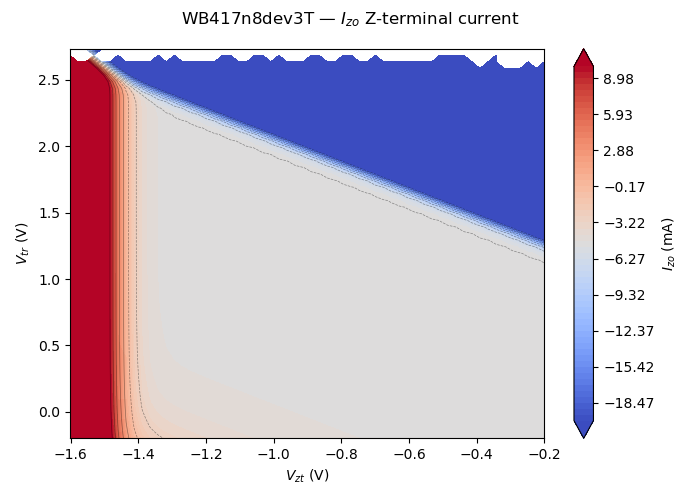

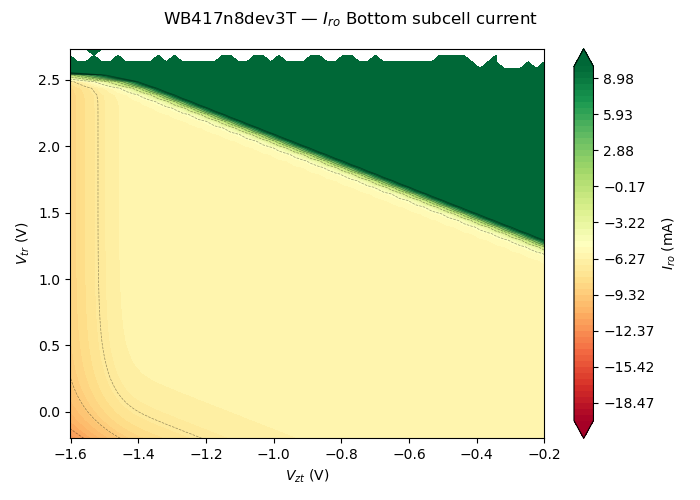

In [31]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T
from scipy.interpolate import RegularGridInterpolator

# ── Device definition ────────────────────────────────────────────────────────
A = 1
Aratio = 0.66

WB417n8dev3T = pvc.Tandem3T()
WB417n8dev3T.set(name='WB417n8dev3T', Rz=2)

WB417n8dev3T.top.set(Eg=1.861, n=[1, 1], J0ratio=[20, 30], Jext=0.011,
                     Gsh=3e-8, pn=1, Rser=0.005)
WB417n8dev3T.top.set(area=A, lightarea=0.98)
WB417n8dev3T.top.RBB_dict = {'method': 'JFG', 'mrb': 10, 'J0rb': 4e-4, 'Vrb': 0}

WB417n8dev3T.bot.set(Eg=1.419, n=[1, 1], J0ratio=[20, 25], Jext=0.009,
                     Gsh=7e-8, pn=-1, Rser=0.005)
WB417n8dev3T.bot.set(beta=4, area=A * Aratio, lightarea=0.65)
WB417n8dev3T.bot.RBB_dict = {'method': 'JFG', 'mrb': 10., 'J0rb': 0.5, 'Vrb': 0.}

# ── Get special points for initial axis ranges ────────────────────────────────
sp = WB417n8dev3T.specialpoints(meastype='CT')
print(f"Voc3: Vzt={sp.Vzt[0]:.3f}, Vrz={sp.Vrz[0]:.3f}, Vtr={sp.Vtr[0]:.3f} V")

# ── Solver ────────────────────────────────────────────────────────────────────
n_pts = 60
Vzt_min, Vzt_max = -0.2, sp.Vzt[0] * 1.1
Vtr_min, Vtr_max = -0.2, sp.Vtr[0] * 1.1

Vzt_1d = np.linspace(Vzt_min, Vzt_max, n_pts)
Vtr_1d = np.linspace(Vtr_min, Vtr_max, n_pts)
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

iv = IV3T(name='contour', meastype='CT',
          area=WB417n8dev3T.lightarea, shape=(n_pts, n_pts))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid
iv.xkey = 'Vzt'
iv.ykey = 'Vtr'
iv.x = Vzt_1d
iv.y = Vtr_1d

WB417n8dev3T.I3Trel(iv)

Iro_mA = iv.Iro * -1e3
Izo_mA = iv.Izo * -1e3

# ── Interpolators (shared by both figures) ────────────────────────────────────
interp_iro = RegularGridInterpolator((Vtr_1d, Vzt_1d), Iro_mA,
                                      bounds_error=False, fill_value=np.nan)
interp_izo = RegularGridInterpolator((Vtr_1d, Vzt_1d), Izo_mA,
                                      bounds_error=False, fill_value=np.nan)

# ── Shared annotation builder ─────────────────────────────────────────────────
def make_annot(ax):
    return ax.annotate('', xy=(0, 0), xytext=(10, 10),
                        textcoords='offset points',
                        bbox=dict(boxstyle='round,pad=0.4',
                                  fc='white', alpha=0.85, ec='gray'),
                        fontsize=8, visible=False)

def make_hover(fig, ax, annot):
    def on_move(event):
        if event.inaxes == ax:
            vzt = event.xdata
            vtr = event.ydata
            vrz = -vzt - vtr
            iro = interp_iro([[vtr, vzt]])[0]
            izo = interp_izo([[vtr, vzt]])[0]
            annot.set_text(
                f'Vzt = {vzt:.3f} V\n'
                f'Vtr = {vtr:.3f} V\n'
                f'Vrz = {vrz:.3f} V\n'
                f'Iro = {iro:.2f} mA\n'
                f'Izo = {izo:.2f} mA'
            )
            annot.xy = (vzt, vtr)
            annot.set_visible(True)
        else:
            annot.set_visible(False)
        fig.canvas.draw_idle()
    fig.canvas.mpl_connect('motion_notify_event', on_move)

# ── Figure 1: Iro ─────────────────────────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(7, 5))
fig1.suptitle('WB417n8dev3T — $I_{ro}$ Bottom subcell current', fontsize=12)

cf1 = ax1.contourf(Vzt_grid, Vtr_grid, Iro_mA,
                   levels=np.linspace(-20, 10, 60),
                   cmap='RdYlGn', extend='both')
ax1.contour(Vzt_grid, Vtr_grid, Iro_mA,
            levels=np.linspace(-20, 10, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig1.colorbar(cf1, ax=ax1).set_label('$I_{ro}$ (mA)')
ax1.set_xlabel('$V_{zt}$ (V)')
ax1.set_ylabel('$V_{tr}$ (V)')

annot1 = make_annot(ax1)
make_hover(fig1, ax1, annot1)
plt.tight_layout()

# ── Figure 2: Izo ─────────────────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 5))
fig2.suptitle('WB417n8dev3T — $I_{zo}$ Z-terminal current', fontsize=12)

cf2 = ax2.contourf(Vzt_grid, Vtr_grid, Izo_mA,
                   levels=np.linspace(-20, 10, 60),
                   cmap='coolwarm', extend='both')
ax2.contour(Vzt_grid, Vtr_grid, Izo_mA,
            levels=np.linspace(-20, 10, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig2.colorbar(cf2, ax=ax2).set_label('$I_{zo}$ (mA)')
ax2.set_xlabel('$V_{zt}$ (V)')
ax2.set_ylabel('$V_{tr}$ (V)')

annot2 = make_annot(ax2)
make_hover(fig2, ax2, annot2)
plt.tight_layout()

plt.show()

In [ ]:

TTT1sun= pvc.Tandem3T()
TTT1sun.set(name='Ideal 3T Device', Rz = 2.3)
TTT1sun.top.set(Eg=1.87, J0ratio=[ 80., 22.], Jext=0.011, Gsh=1e-8, area=A)
TTT1sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}
TTT1sun.bot.set(Eg=1.419, J0ratio=[10., 15.], Jext=0.006, Gsh= 5e-5,pn=1)
TTT1sun.bot.set(Rser=0.2, beta=5, area=A*Aratio)
TTT1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T
from scipy.interpolate import RegularGridInterpolator

# ── Device definition ────────────────────────────────────────────────────────

A=1
Aratio=0.66
TTT1sun = pvc.Tandem3T()


TTT1sun.set(name='Model Fit', Rz = 2)
TTT1sun.top.set(Eg=1.861, n=[1, 3.4], J0ratio=[200, 270], Jext=0.0112, Gsh=3e-4,pn=1, Rser=1.5)
TTT1sun.top.set( area=A, lightarea=0.98)
TTT1sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}



TTT1sun.bot.set(Eg=1.419, n=[1, 4], J0ratio=[50,25], Jext=0.0085, Gsh=6e-3, pn=-1, Rser=0.001)

TTT1sun.bot.set( beta=15, area=A*Aratio, lightarea=0.65)
TTT1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}

# ── Get special points for initial axis ranges ────────────────────────────────
sp = TTT1sun.specialpoints(meastype='CT')
print(f"Voc3: Vzt={sp.Vzt[0]:.3f}, Vrz={sp.Vrz[0]:.3f}, Vtr={sp.Vtr[0]:.3f} V")

# ── Solver ────────────────────────────────────────────────────────────────────
n_pts = 150
Vzt_min, Vzt_max = -1.5, 1.5
Vtr_min, Vtr_max = -2, 2

Vzt_1d = np.linspace(Vzt_min, Vzt_max, n_pts)
Vtr_1d = np.linspace(Vtr_min, Vtr_max, n_pts)
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

iv = IV3T(name='contour', meastype='CT',
          area=TTT1sun.lightarea, shape=(n_pts, n_pts))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid
iv.xkey = 'Vzt'
iv.ykey = 'Vtr'
iv.x = Vzt_1d
iv.y = Vtr_1d

TTT1sun.I3Trel(iv)

Iro_mA = iv.Iro * 1e3
Izo_mA = iv.Izo * 1e3

# ── Interpolators (shared by both figures) ────────────────────────────────────
interp_iro = RegularGridInterpolator((Vtr_1d, Vzt_1d), Iro_mA,
                                      bounds_error=False, fill_value=np.nan)
interp_izo = RegularGridInterpolator((Vtr_1d, Vzt_1d), Izo_mA,
                                      bounds_error=False, fill_value=np.nan)

# ── Shared annotation builder ─────────────────────────────────────────────────
def make_annot(ax):
    return ax.annotate('', xy=(0, 0), xytext=(10, 10),
                        textcoords='offset points',
                        bbox=dict(boxstyle='round,pad=0.4',
                                  fc='white', alpha=0.85, ec='gray'),
                        fontsize=8, visible=False)

def make_hover(fig, ax, annot):
    def on_move(event):
        if event.inaxes == ax:
            vzt = event.ydata
            vtr = event.xdata
            vrz = -vzt - vtr
            iro = -interp_iro([[vtr, vzt]])[0]
            izo = -interp_izo([[vtr, vzt]])[0]
            annot.set_text(
                f'Vzt = {vzt:.3f} V\n'
                f'Vtr = {vtr:.3f} V\n'
                f'Vrz = {vrz:.3f} V\n'
                f'Iro = {iro:.2f} mA\n'
                f'Izo = {izo:.2f} mA'
            )
            annot.xy = (vzt, vtr)
            annot.set_visible(True)
        else:
            annot.set_visible(False)
        fig.canvas.draw_idle()
    fig.canvas.mpl_connect('motion_notify_event', on_move)

# ── Figure 1: Iro ─────────────────────────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(7, 5))
fig1.suptitle('Non Ideal 3TT Device 1 sun: $I_{ro}$ R-terminal current', fontsize=12)

cf1 = ax1.contourf(Vtr_grid, -Vzt_grid,  -Iro_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='twilight', extend='both')
ax1.contour(Vtr_grid, -Vzt_grid, -Iro_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig1.colorbar(cf1, ax=ax1).set_label('$I_{ro}$ (mA)')
ax1.set_ylabel('$V_{zt}$ (V)')
ax1.set_xlabel('$V_{tr}$ (V)')

annot1 = make_annot(ax1)
make_hover(fig1, ax1, annot1)
plt.tight_layout()

# ── Figure 2: Izo ─────────────────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 5))
fig2.suptitle('Non Ideal 3TT Device 1 sun: $I_{zo}$ Z-terminal current', fontsize=12)

cf2 = ax2.contourf(Vtr_grid, -Vzt_grid, -Izo_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='coolwarm', extend='both')
ax2.contour(Vtr_grid, -Vzt_grid, -Izo_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig2.colorbar(cf2, ax=ax2).set_label('$I_{zo}$ (mA)')
ax2.set_ylabel('$V_{zt}$ (V)')
ax2.set_xlabel('$V_{tr}$ (V)')

annot2 = make_annot(ax2)
make_hover(fig2, ax2, annot2)
plt.tight_layout()

plt.show()




In [ ]:
import numpy as np
import pandas as pd
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T

# ── 1. Device Definition ──────────────────────────────────────────────────────

A=1
Aratio=0.66
TTT1sun = pvc.Tandem3T()


TTT1sun.set(name='Model Fit', Rz = 2)
TTT1sun.top.set(Eg=1.861, n=[1, 3.4], J0ratio=[200, 270], Jext=0.0112, Gsh=3e-4,pn=1, Rser=1.5)
TTT1sun.top.set( area=A, lightarea=0.98)
TTT1sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}



TTT1sun.bot.set(Eg=1.419, n=[1, 4], J0ratio=[50,25], Jext=0.0085, Gsh=6e-3, pn=-1, Rser=0.001)

TTT1sun.bot.set( beta=15, area=A*Aratio, lightarea=0.65)
TTT1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}

# ── 2. Grid Setup & Solver (0.5 V Fixed Step Sizes) ─────────────────────────
# Define bounds
Vtr_min, Vtr_max = -2.2, 2
Vzt_min, Vzt_max = -1.2, 1
step_size = 0.05

# Generate 1D voltage arrays using np.arange to guarantee exact 0.5 V steps.
# We add (step_size / 2) to the max boundary to safely include the upper endpoint.
Vtr_1d = np.arange(Vtr_min, Vtr_max + (step_size / 2), step_size)
Vzt_1d = np.arange(Vzt_min, Vzt_max + (step_size / 2), step_size)

# Print verification to console
print("📍 Confirmed Vtr voltage points (Step = 0.05V):")
print(Vtr_1d)
print("\n📍 Confirmed Vzt voltage points (Step = 0.05V):")
print(Vzt_1d)

# Create 2D grids
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

# Determine dimensions dynamically based on arange outputs
n_pts_vtr = len(Vtr_1d)
n_pts_vzt = len(Vzt_1d)

# Run the 3T IV solver
iv = IV3T(name='contour', meastype='CT', area=TTT1sun.lightarea, shape=(n_pts_vtr, n_pts_vzt))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid

TTT1sun.I3Trel(iv)

# Calculate the R-terminal current (mA)
Iro_mA = -iv.Iro * 1e3

# ── 3. Build & Save the Matrix DataFrame ──────────────────────────────────────
# Create the Pandas DataFrame with Vtr as rows and Vzt as columns
df_matrix = pd.DataFrame(data=Iro_mA, index=Vtr_1d, columns=Vzt_1d)

# Round indexes and headers for visual cleanliness
df_matrix.index = df_matrix.index.to_series().round(4)
df_matrix.columns = df_matrix.columns.to_series().round(4)

# Set matrix label names
df_matrix.index.name = 'Vtr (V)'
df_matrix.columns.name = 'Vzt (V)'

# Save to your local directory
output_file = 'Iro_current_matrix_full_10.csv'
df_matrix.to_csv(output_file)

print(f"\n✅ Success! Generated a {n_pts_vtr}x{n_pts_vzt} data grid.")
print(f"💾 Saved as: '{output_file}'")


In [32]:
import pandas as pd
import numpy as np
from scipy.interpolate import RegularGridInterpolator

# ── 1. Load Model Data Matrix ─────────────────────────────────────────────────
model_file = '/Users/dcollins/Library/CloudStorage/OneDrive-NLR/Iro_current_matrix_full_5.csv' 
print(f"Loading model data from {model_file}...")
model_df = pd.read_csv(model_file, index_col=0)

# Convert axes to float arrays
Vtr_model = model_df.index.to_numpy(dtype=float)
Vzt_model = model_df.columns.to_numpy(dtype=float)
Iro_model = model_df.to_numpy(dtype=float)

# Create the 2D interpolator from the model matrix
interpolator = RegularGridInterpolator(
    (Vtr_model, Vzt_model), Iro_model, 
    bounds_error=False, fill_value=np.nan
)

# ── 2. Load Experimental Data Matrix ──────────────────────────────────────────
# UPDATE THIS with your actual excel file name
experimental_file ='/Users/dcollins/Library/CloudStorage/OneDrive-NLR/1sun_table.csv' 
print(f"Loading experimental matrix from {experimental_file}...")

# Read the excel file, treating the first row as columns and first column as index
exp_df_matrix = pd.read_excel(experimental_file, index_col=0)

# Ensure the column headers and row indexes are treated as numbers (floats)
exp_df_matrix.columns = exp_df_matrix.columns.astype(float)
exp_df_matrix.index = exp_df_matrix.index.astype(float)

# Flatten (stack) the 2D matrix into a 1D list of coordinates: [Vtr, Vzt, Iro]
exp_flat = exp_df_matrix.stack().reset_index()
exp_flat.columns = ['Vtr', 'Vzt', 'Iro']

# Drop any blank/NaN measurements from the experiment
exp_flat = exp_flat.dropna()

Vtr_exp = exp_flat['Vtr'].to_numpy()
Vzt_exp = exp_flat['Vzt'].to_numpy()
Iro_exp = exp_flat['Iro'].to_numpy()

# ── 3. Interpolate and Compare ────────────────────────────────────────────────
print("Interpolating model values at experimental coordinates...")
coords_exp = np.column_stack((Vtr_exp, Vzt_exp))

# Get the model's prediction for each experimental point
Iro_model_predicted = interpolator(coords_exp)

# Filter out points that fell outside the model's simulated voltage boundaries
valid_mask = ~np.isnan(Iro_model_predicted)
Iro_exp_valid = Iro_exp[valid_mask]
Iro_model_valid = Iro_model_predicted[valid_mask]

points_used = np.sum(valid_mask)
points_dropped = len(Iro_exp) - points_used
if points_dropped > 0:
    print(f"Warning: {points_dropped} experimental points were outside the model's voltage range and ignored.")

# ── 4. Calculate Metrics (R-squared and RMSE) ─────────────────────────────────
ss_res = np.sum((Iro_exp_valid - Iro_model_valid)**2) 
ss_tot = np.sum((Iro_exp_valid - np.mean(Iro_exp_valid))**2) 

# Handle edge case where experimental data is completely flat (variance = 0)
if ss_tot == 0:
    r_squared = float('nan')
else:
    r_squared = 1 - (ss_res / ss_tot)

rmse = np.sqrt(np.mean((Iro_exp_valid - Iro_model_valid)**2))

print("\n" + "="*30)
print("📊 MODEL VALIDATION RESULTS")
print("="*30)
print(f"Data Points Compared : {points_used}")
print(f"R-squared (R²)       : {r_squared:.4f}")
print(f"RMSE                 : {rmse:.4f} mA")
print("="*30)


Loading model data from /Users/dcollins/Library/CloudStorage/OneDrive-NLR/Iro_current_matrix_full_5.csv...
Loading experimental matrix from /Users/dcollins/Library/CloudStorage/OneDrive-NLR/1sun_table.csv...


ValueError: Excel file format cannot be determined, you must specify an engine manually.

In [33]:
import numpy as np
import pandas as pd
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T

# ── 1. Device Definition ──────────────────────────────────────────────────────



A=1
Aratio=0.66
TTT1sun = pvc.Tandem3T()


TTT1sun.set(name='Model Fit', Rz = 2)
TTT1sun.top.set(Eg=1.861, n=[1, 3.4], J0ratio=[200, 270], Jext=0.011, Gsh=3e-4,pn=1, Rser=1.5)
TTT1sun.top.set( area=A, lightarea=0.98)
TTT1sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}



TTT1sun.bot.set(Eg=1.419, n=[1, 4], J0ratio=[50,25], Jext=0.006, Gsh=6e-3, pn=-1, Rser=0.001)

TTT1sun.bot.set( beta=15, area=A*Aratio, lightarea=0.65)
TTT1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}

# ── 2. Grid Setup & Solver (0.05 V Fixed Step Sizes) ─────────────────────────
# Define bounds
Vtr_min, Vtr_max = -2.2, 2.2
Vzt_min, Vzt_max = -1.3, 1.3
step_size = 0.1

# Generate 1D voltage arrays using np.arange to guarantee exact steps.
Vtr_1d = np.arange(Vtr_min, Vtr_max + (step_size / 2), step_size)
Vzt_1d = np.arange(Vzt_min, Vzt_max + (step_size / 2), step_size)

# Print verification to console
print("📍 Confirmed Vtr voltage points (Step = 0.05V):")
print(Vtr_1d)
print("\n📍 Confirmed Vzt voltage points (Step = 0.05V):")
print(Vzt_1d)

# Create 2D grids
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

# Determine dimensions dynamically based on arange outputs
n_pts_vtr = len(Vtr_1d)
n_pts_vzt = len(Vzt_1d)

# Run the 3T IV solver
iv = IV3T(name='contour', meastype='CT', area=TTT1sun.lightarea, shape=(n_pts_vtr, n_pts_vzt))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid

TTT1sun.I3Trel(iv)

# Calculate the R-terminal current (mA)
Iro_mA = -iv.Iro * 1e3

# ── 3. Build & Save the Matrix DataFrame (MAX to MIN) ─────────────────────────
# ── 3. Build & Save the Matrix DataFrame (MAX to MIN) ─────────────────────────
# Create the Pandas DataFrame with Vtr as rows and Vzt as columns
df_matrix = pd.DataFrame(data=Iro_mA, index=Vtr_1d, columns=Vzt_1d)

# SORT MAX TO MIN: Reverse the rows (index) and columns
df_matrix = df_matrix.sort_index(ascending=False)
df_matrix = df_matrix[df_matrix.columns.sort_values(ascending=False)]

# LIMIT VALUES: Replace any values greater than 100 mA with NaN (blank cells)
# (If you want to cap them at 100 instead, use: df_matrix = df_matrix.clip(upper=100))
df_matrix[df_matrix > 100.0] = np.nan

# Round indexes and headers for visual cleanliness
df_matrix.index = df_matrix.index.to_series().round(4)
df_matrix.columns = df_matrix.columns.to_series().round(4)

# Set matrix label names
df_matrix.index.name = 'Vtr (V)'
df_matrix.columns.name = 'Vzt (V)'

# Save to your local directory
output_file = 'Iro_current_matrix_full_9.csv'
df_matrix.to_csv(output_file)

print(f"\n✅ Success! Generated a {n_pts_vtr}x{n_pts_vzt} data grid (Sorted Max to Min).")
print(f"⚠️ Note: All current values above 100 mA have been excluded (replaced with blank cells).")
print(f"💾 Saved as: '{output_file}'")



📍 Confirmed Vtr voltage points (Step = 0.05V):
[-2.20000000e+00 -2.10000000e+00 -2.00000000e+00 -1.90000000e+00
 -1.80000000e+00 -1.70000000e+00 -1.60000000e+00 -1.50000000e+00
 -1.40000000e+00 -1.30000000e+00 -1.20000000e+00 -1.10000000e+00
 -1.00000000e+00 -9.00000000e-01 -8.00000000e-01 -7.00000000e-01
 -6.00000000e-01 -5.00000000e-01 -4.00000000e-01 -3.00000000e-01
 -2.00000000e-01 -1.00000000e-01  1.77635684e-15  1.00000000e-01
  2.00000000e-01  3.00000000e-01  4.00000000e-01  5.00000000e-01
  6.00000000e-01  7.00000000e-01  8.00000000e-01  9.00000000e-01
  1.00000000e+00  1.10000000e+00  1.20000000e+00  1.30000000e+00
  1.40000000e+00  1.50000000e+00  1.60000000e+00  1.70000000e+00
  1.80000000e+00  1.90000000e+00  2.00000000e+00  2.10000000e+00
  2.20000000e+00]

📍 Confirmed Vzt voltage points (Step = 0.05V):
[-1.30000000e+00 -1.20000000e+00 -1.10000000e+00 -1.00000000e+00
 -9.00000000e-01 -8.00000000e-01 -7.00000000e-01 -6.00000000e-01
 -5.00000000e-01 -4.00000000e-01 -3.000000

In [34]:
import numpy as np
import pandas as pd
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T

# ── 1. Device Definition ──────────────────────────────────────────────────────
A = 1
Aratio = 0.66

TTT1sun = pvc.Tandem3T()
TTT1sun.set(name='Model Fit', Rz=2)

TTT1sun.top.set(Eg=1.861, n=[1, 3], J0ratio=[400, 425], Jext=0.010, Gsh=1e-8, pn=1, Rser=2)
TTT1sun.top.set(area=A, lightarea=0.98)
TTT1sun.top.RBB_dict = {'method': 'JFG', 'mrb': 10., 'J0rb': 1e-4, 'Vrb': 0.}

TTT1sun.bot.set(Eg=1.419, n=[1, 4], J0ratio=[50, 40], Jext=0.006, Gsh=5e-3, pn=-1, Rser=0.5)
TTT1sun.bot.set(beta=15, area=A*Aratio, lightarea=0.65)
TTT1sun.bot.RBB_dict = {'method': 'JFG', 'mrb': 10., 'J0rb': 1e-4, 'Vrb': 0.}

# ── 2. Grid Setup & Solver (0.05 V Fixed Step Sizes) ─────────────────────────
# Define bounds
Vtr_min, Vtr_max = -2.2, 2.2
Vzt_min, Vzt_max = -1.3, 1.3
step_size = 0.1

# Generate 1D voltage arrays using np.arange to guarantee exact steps.
Vtr_1d = np.arange(Vtr_min, Vtr_max + (step_size / 2), step_size)
Vzt_1d = np.arange(Vzt_min, Vzt_max + (step_size / 2), step_size)

# Print verification to console
print("📍 Confirmed Vtr voltage points (Step = 0.05V):")
print(Vtr_1d)
print("\n📍 Confirmed Vzt voltage points (Step = 0.05V):")
print(Vzt_1d)

# Create 2D grids
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

# Determine dimensions dynamically based on arange outputs
n_pts_vtr = len(Vtr_1d)
n_pts_vzt = len(Vzt_1d)

# Run the 3T IV solver
iv = IV3T(name='contour', meastype='CT', area=TTT1sun.lightarea, shape=(n_pts_vtr, n_pts_vzt))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid

TTT1sun.I3Trel(iv)

# Calculate the R-terminal current (mA)
Iro_mA = -iv.Iro * 1e3

# ── 3. Build, Sort, & Save the Matrix DataFrame ──────────────────────────────
# Create the Pandas DataFrame
df_matrix = pd.DataFrame(data=Iro_mA, index=Vtr_1d, columns=Vzt_1d)

# CUSTOM SORT: Vtr (rows) are Max to Min, Vzt (columns) are Min to Max
df_matrix = df_matrix.sort_index(ascending=False)
df_matrix = df_matrix[df_matrix.columns.sort_values(ascending=True)]

# LIMIT VALUES: Replace any values greater than 100 mA with NaN (blank cells)
df_matrix[df_matrix > 100.0] = np.nan

# Round indexes and headers for visual cleanliness
df_matrix.index = df_matrix.index.to_series().round(4)
df_matrix.columns = df_matrix.columns.to_series().round(4)

# Set matrix label names
df_matrix.index.name = 'Vtr (V)'
df_matrix.columns.name = 'Vzt (V)'

# Save to your local directory
output_file = 'Iro_current_matrix_full_11.csv'
df_matrix.to_csv(output_file)

print(f"\n✅ Success! Generated a {n_pts_vtr}x{n_pts_vzt} data grid.")
print(f"💾 Saved as: '{output_file}' with custom sorting.")



📍 Confirmed Vtr voltage points (Step = 0.05V):
[-2.20000000e+00 -2.10000000e+00 -2.00000000e+00 -1.90000000e+00
 -1.80000000e+00 -1.70000000e+00 -1.60000000e+00 -1.50000000e+00
 -1.40000000e+00 -1.30000000e+00 -1.20000000e+00 -1.10000000e+00
 -1.00000000e+00 -9.00000000e-01 -8.00000000e-01 -7.00000000e-01
 -6.00000000e-01 -5.00000000e-01 -4.00000000e-01 -3.00000000e-01
 -2.00000000e-01 -1.00000000e-01  1.77635684e-15  1.00000000e-01
  2.00000000e-01  3.00000000e-01  4.00000000e-01  5.00000000e-01
  6.00000000e-01  7.00000000e-01  8.00000000e-01  9.00000000e-01
  1.00000000e+00  1.10000000e+00  1.20000000e+00  1.30000000e+00
  1.40000000e+00  1.50000000e+00  1.60000000e+00  1.70000000e+00
  1.80000000e+00  1.90000000e+00  2.00000000e+00  2.10000000e+00
  2.20000000e+00]

📍 Confirmed Vzt voltage points (Step = 0.05V):
[-1.30000000e+00 -1.20000000e+00 -1.10000000e+00 -1.00000000e+00
 -9.00000000e-01 -8.00000000e-01 -7.00000000e-01 -6.00000000e-01
 -5.00000000e-01 -4.00000000e-01 -3.000000

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Load Data & Define Cropping Window ---
model_file = 'Iro_current_matrix_full_11.csv'
experimental_file = 'mw808n1_JA.csv'

# 🛑 SET YOUR BOUNDING BOX HERE 🛑
# Adjust these values to crop out the bad edges. 
# (These are example bounds based on standard operating regions)
Vtr_min_crop, Vtr_max_crop = -0.8, 0.7
Vzt_min_crop, Vzt_max_crop = -0.8, 0.2

print(f"Loading Model Data: {model_file}")
print(f"Loading Experimental Data: {experimental_file}")

model_df = pd.read_csv(model_file, index_col=0)
exp_df = pd.read_csv(experimental_file, index_col=0)

# --- 2. Clean and Align Grids ---
model_df.columns = pd.to_numeric(model_df.columns, errors='coerce')
model_df.index = pd.to_numeric(model_df.index, errors='coerce')
exp_df.columns = pd.to_numeric(exp_df.columns, errors='coerce')
exp_df.index = pd.to_numeric(exp_df.index, errors='coerce')

model_df.dropna(axis=0, how='all', inplace=True)
model_df.dropna(axis=1, how='all', inplace=True)
exp_df.dropna(axis=0, how='all', inplace=True)
exp_df.dropna(axis=1, how='all', inplace=True)

common_cols = model_df.columns.intersection(exp_df.columns)
common_rows = model_df.index.intersection(exp_df.index)

# --- 2.5 APPLY THE CROPPING WINDOW ---
# Filter the rows and columns to only keep those inside your bounding box
cropped_rows = [r for r in common_rows if Vtr_min_crop <= r <= Vtr_max_crop]
cropped_cols = [c for c in common_cols if Vzt_min_crop <= c <= Vzt_max_crop]

model_aligned = model_df.loc[cropped_rows, cropped_cols]
exp_aligned = exp_df.loc[cropped_rows, cropped_cols]

# --- 3. Calculate Difference on Absolute Values ---
model_abs = np.abs(model_aligned)
exp_abs = np.abs(exp_aligned)
residual_df = model_abs - exp_abs

# --- 4. Calculate R-squared and RMSE ---
model_flat = model_abs.to_numpy().flatten()
exp_flat = exp_abs.to_numpy().flatten()

valid_mask = ~np.isnan(model_flat) & ~np.isnan(exp_flat)
model_valid = model_flat[valid_mask]
exp_valid = exp_flat[valid_mask]

# R-squared Calculation
ss_res = np.sum((exp_valid - model_valid)**2)
ss_tot = np.sum((exp_valid - np.mean(exp_valid))**2)
r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0

rmse = np.sqrt(np.mean((exp_valid - model_valid)**2))

print("\n" + "="*45)
print("📊 CROPPED BOX-TO-BOX VALIDATION (ABSOLUTE VALUES)")
print("="*45)
print(f"Voltage Window       : Vtr[{Vtr_min_crop} to {Vtr_max_crop}], Vzt[{Vzt_min_crop} to {Vzt_max_crop}]")
print(f"Data Points Compared : {len(exp_valid)}")
print(f"R-squared (R²)       : {r_squared:.4f}")
print(f"RMSE                 : {rmse:.4f} mA")
print("="*45)

# --- 5. Plot the Cropped Heatmap ---
plt.figure(figsize=(10, 7))
sns.heatmap(residual_df, cmap='coolwarm', center=0, cbar_kws={'label': 'Error (mA)'})

plt.title('Cropped Heatmap of Error (Model - Experiment)', fontsize=16)
plt.xlabel('Vzt (V)', fontsize=12)
plt.ylabel('Vtr (V)', fontsize=12)
plt.gca().invert_yaxis() 
plt.tight_layout()
plt.show()


Loading Model Data: Iro_current_matrix_full_11.csv
Loading Experimental Data: mw808n1_JA.csv


FileNotFoundError: [Errno 2] No such file or directory: 'mw808n1_JA.csv'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Load Data ---
# Replace these with your actual filenames if they change
model_file = 'Iro_current_matrix_full_11.csv'
experimental_file = 'mw808n1_JA.csv'

print(f"Loading Model Data: {model_file}")
print(f"Loading Experimental Data: {experimental_file}")

model_df = pd.read_csv(model_file, index_col=0)
exp_df = pd.read_csv(experimental_file, index_col=0)

# --- 2. Clean and Align Grids ---
# Clean the column/index names by converting to numeric, coercing any text/errors to NaN
model_df.columns = pd.to_numeric(model_df.columns, errors='coerce')
model_df.index = pd.to_numeric(model_df.index, errors='coerce')
exp_df.columns = pd.to_numeric(exp_df.columns, errors='coerce')
exp_df.index = pd.to_numeric(exp_df.index, errors='coerce')

# Drop any rows/columns that failed to convert (e.g., metadata rows)
model_df.dropna(axis=0, how='all', inplace=True)
model_df.dropna(axis=1, how='all', inplace=True)
exp_df.dropna(axis=0, how='all', inplace=True)
exp_df.dropna(axis=1, how='all', inplace=True)

# Align the experimental data to the model's grid
# This finds common Vtr and Vzt coordinates and aligns them perfectly for a 1-to-1 comparison.
common_cols = model_df.columns.intersection(exp_df.columns)
common_rows = model_df.index.intersection(exp_df.index)

model_aligned = model_df.loc[common_rows, common_cols]
exp_aligned = exp_df.loc[common_rows, common_cols]

# --- 3. Calculate Difference on Absolute Values ---
# Take the absolute value of both dataframes to ignore negative sign conventions
model_abs = np.abs(model_aligned)
exp_abs = np.abs(exp_aligned)

# Calculate the residual (error) -> Model Current - Experimental Current
residual_df = model_abs - exp_abs

# --- 4. Calculate R-squared and RMSE ---
# Flatten the dataframes to 1D arrays, dropping any non-overlapping points
model_flat = model_abs.to_numpy().flatten()
exp_flat = exp_abs.to_numpy().flatten()

valid_mask = ~np.isnan(model_flat) & ~np.isnan(exp_flat)
model_valid = model_flat[valid_mask]
exp_valid = exp_flat[valid_mask]

# R-squared Calculation
ss_res = np.sum((exp_valid - model_valid)**2)
ss_tot = np.sum((exp_valid - np.mean(exp_valid))**2)
r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0

# RMSE Calculation
rmse = np.sqrt(np.mean((exp_valid - model_valid)**2))

print("\n" + "="*45)
print("📊 ALIGNED BOX-TO-BOX VALIDATION (ABSOLUTE VALUES)")
print("="*45)
print(f"Data Points Compared : {len(exp_valid)}")
print(f"R-squared (R²)       : {r_squared:.4f}")
print(f"RMSE                 : {rmse:.4f} mA")
print("="*45)

# --- 5. Plot the Heatmap of the Residuals ---
plt.figure(figsize=(12, 9))
# We use coolwarm so 0 error is white, positive error is red, negative error is blue
sns.heatmap(residual_df, cmap='coolwarm', center=0, cbar_kws={'label': 'Error (mA)'})

plt.title('Heatmap of Error (Model Current - Experimental Current)', fontsize=16)
plt.xlabel('Vzt (V)', fontsize=12)
plt.ylabel('Vtr (V)', fontsize=12)

# Ensure the Y-axis matches the orientation of your CSV (Max to Min)
plt.gca().invert_yaxis() 

# Display the plot
plt.tight_layout()
plt.show()


In [ ]:

# Universally set the font family to Arial and size to 18
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial'],
    'font.size': 15,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15
})


Voc3: Vzt=-1.435, Vrz=-1.013, Vtr=2.448 V


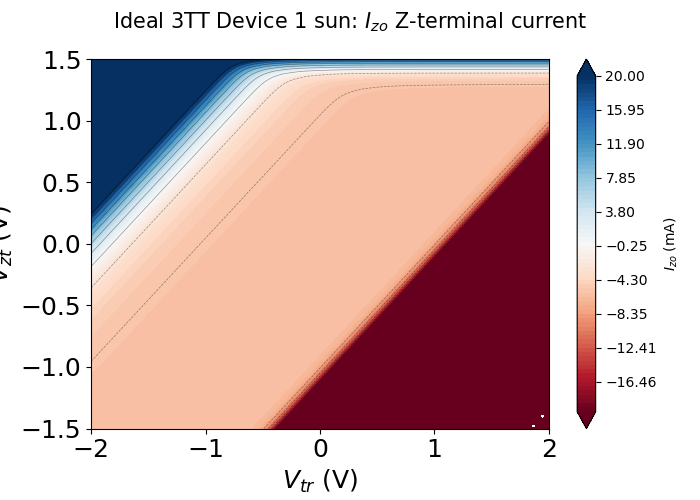

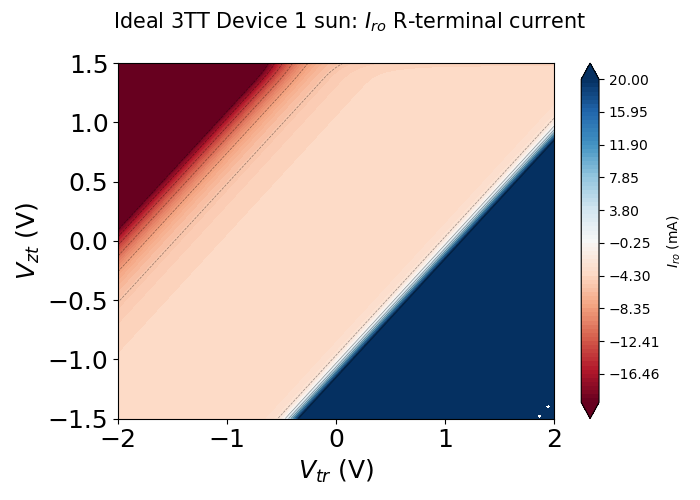

In [36]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T
from scipy.interpolate import RegularGridInterpolator

# ── Device definition ────────────────────────────────────────────────────────
A = 1
Aratio = 0.66


TTT1sunI= pvc.Tandem3T()
TTT1sunI.set(name='Ideal 3T Device', Rz = 2.3)
TTT1sunI.top.set(Eg=1.87,  n=[1,1.8], J0ratio=[ 80., 22.], Jext=0.010, Gsh=1e-8, pn=1, area=A, Rser=0.2)
TTT1sunI.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}
TTT1sunI.bot.set(Eg=1.419,  n=[1, 2], J0ratio=[10., 15.], Jext=0.006, Gsh= 5e-5,pn=-1)
TTT1sunI.bot.set(Rser=0.2, beta=5, area=A*Aratio)
TTT1sunI.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}


# ── Get special points for initial axis ranges ────────────────────────────────
sp = TTT1sunI.specialpoints(meastype='CT')
print(f"Voc3: Vzt={sp.Vzt[0]:.3f}, Vrz={sp.Vrz[0]:.3f}, Vtr={sp.Vtr[0]:.3f} V")

# ── Solver ────────────────────────────────────────────────────────────────────
n_pts = 150
Vzt_min, Vzt_max = -1.5, 1.5
Vtr_min, Vtr_max = -2, 2

Vzt_1d = np.linspace(Vzt_min, Vzt_max, n_pts)
Vtr_1d = np.linspace(Vtr_min, Vtr_max, n_pts)
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

iv = IV3T(name='contour', meastype='CT',
          area=TTT1sunI.lightarea, shape=(n_pts, n_pts))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid
iv.xkey = 'Vzt'
iv.ykey = 'Vtr'
iv.x = Vzt_1d
iv.y = Vtr_1d

TTT1sunI.I3Trel(iv)


Iro_mA = iv.Iro * 1e3
Izo_mA = iv.Izo * 1e3

# ── Interpolators (shared by both figures) ────────────────────────────────────
interp_iro = RegularGridInterpolator((Vtr_1d, Vzt_1d), Iro_mA,
                                      bounds_error=False, fill_value=np.nan)
interp_izo = RegularGridInterpolator((Vtr_1d, Vzt_1d), Izo_mA,
                                      bounds_error=False, fill_value=np.nan)

# ── Shared annotation builder ─────────────────────────────────────────────────
def make_annot(ax):
    return ax.annotate('', xy=(0, 0), xytext=(10, 10),
                        textcoords='offset points',
                        bbox=dict(boxstyle='round,pad=0.4',
                                  fc='white', alpha=0.85, ec='gray'),
                        fontsize=8, visible=False)

def make_hover(fig, ax, annot):
    def on_move(event):
        if event.inaxes == ax:
            vzt = event.ydata
            vtr = event.xdata
            vrz = -vzt - vtr
            iro = -interp_iro([[vtr, vzt]])[0]
            izo = -interp_izo([[vtr, vzt]])[0]
            annot.set_text(
                f'Vzt = {vzt:.3f} V\n'
                f'Vtr = {vtr:.3f} V\n'
                f'Vrz = {vrz:.3f} V\n'
                f'Iro = {iro:.2f} mA\n'
                f'Izo = {izo:.2f} mA'
            )
            annot.xy = (vzt, vtr)
            annot.set_visible(True)
        else:
            annot.set_visible(False)
        fig.canvas.draw_idle()
    fig.canvas.mpl_connect('motion_notify_event', on_move)

# ── Figure 1: Iro ─────────────────────────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(7, 5))
fig1.suptitle('Ideal 3TT Device 1 sun: $I_{ro}$ R-terminal current', fontsize=15)

cf1 = ax1.contourf(Vtr_grid, -Vzt_grid,  -Iro_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='RdBu', extend='both')
ax1.contour(Vtr_grid, -Vzt_grid, -Iro_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig1.colorbar(cf1, ax=ax1).set_label('$I_{ro}$ (mA)')
ax1.set_ylabel('$V_{zt}$ (V)',fontsize= 18)
ax1.set_xlabel('$V_{tr}$ (V)',fontsize= 18)
plt.tick_params(axis='both', which='major', labelsize=18)

annot1 = make_annot(ax1)
make_hover(fig1, ax1, annot1)
plt.tight_layout()

# ── Figure 2: Izo ─────────────────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 5))
fig2.suptitle('Ideal 3TT Device 1 sun: $I_{zo}$ Z-terminal current', fontsize=15)

cf2 = ax2.contourf(Vtr_grid, -Vzt_grid, -Izo_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='RdBu', extend='both')
ax2.contour(Vtr_grid, -Vzt_grid, -Izo_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig2.colorbar(cf2, ax=ax2).set_label('$I_{zo}$ (mA)')
ax2.set_ylabel('$V_{zt}$ (V)', fontsize= 18)
ax2.set_xlabel('$V_{tr}$ (V)',fontsize= 18)

annot2 = make_annot(ax2)
make_hover(fig2, ax2, annot2)
plt.tight_layout()
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()



In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T
from scipy.interpolate import RegularGridInterpolator

# ── Device definition ────────────────────────────────────────────────────────
A = 1
Aratio = 0.66

TTT0p5sun = pvc.Tandem3T()
TTT0p5sun.set(name='Ideal 3T Device', Rz = 2.3)
TTT0p5sun.top.set(Eg=1.87, J0ratio=[ 80., 22.], Jext=0.005, Gsh=1e-8,pn=1, area=A)
TTT0p5sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}
TTT0p5sun.bot.set(Eg=1.419, J0ratio=[10., 15.], Jext=0.003, Gsh= 5e-5,pn=-1)
TTT0p5sun.bot.set(Rser=0.2, beta=5, area=A*Aratio)
TTT0p5sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}


# ── Get special points for initial axis ranges ────────────────────────────────
sp = TTT0p5sun.specialpoints(meastype='CT')
print(f"Voc3: Vzt={sp.Vzt[0]:.3f}, Vrz={sp.Vrz[0]:.3f}, Vtr={sp.Vtr[0]:.3f} V")

# ── Solver ────────────────────────────────────────────────────────────────────
n_pts = 150
Vzt_min, Vzt_max = -1.5, 1.5
Vtr_min, Vtr_max = -2, 2

Vzt_1d = np.linspace(Vzt_min, Vzt_max, n_pts)
Vtr_1d = np.linspace(Vtr_min, Vtr_max, n_pts)
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

iv = IV3T(name='contour', meastype='CT',
          area=TTT0p5sun.lightarea, shape=(n_pts, n_pts))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid
iv.xkey = 'Vzt'
iv.ykey = 'Vtr'
iv.x = Vzt_1d
iv.y = Vtr_1d

TTT0p5sun.I3Trel(iv)

Iro_mA = iv.Iro * 1e3
Izo_mA = iv.Izo * 1e3


Iro_mA = iv.Iro * 1e3
Izo_mA = iv.Izo * 1e3

# ── Interpolators (shared by both figures) ────────────────────────────────────
interp_iro = RegularGridInterpolator((Vtr_1d, Vzt_1d), Iro_mA,
                                      bounds_error=False, fill_value=np.nan)
interp_izo = RegularGridInterpolator((Vtr_1d, Vzt_1d), Izo_mA,
                                      bounds_error=False, fill_value=np.nan)

# ── Shared annotation builder ─────────────────────────────────────────────────
def make_annot(ax):
    return ax.annotate('', xy=(0, 0), xytext=(10, 10),
                        textcoords='offset points',
                        bbox=dict(boxstyle='round,pad=0.4',
                                  fc='white', alpha=0.85, ec='gray'),
                        fontsize=8, visible=False)

def make_hover(fig, ax, annot):
    def on_move(event):
        if event.inaxes == ax:
            vzt = event.ydata
            vtr = event.xdata
            vrz = -vzt - vtr
            iro = -interp_iro([[vtr, vzt]])[0]
            izo = -interp_izo([[vtr, vzt]])[0]
            annot.set_text(
                f'Vzt = {vzt:.3f} V\n'
                f'Vtr = {vtr:.3f} V\n'
                f'Vrz = {vrz:.3f} V\n'
                f'Iro = {iro:.2f} mA\n'
                f'Izo = {izo:.2f} mA'
            )
            annot.xy = (vzt, vtr)
            annot.set_visible(True)
        else:
            annot.set_visible(False)
        fig.canvas.draw_idle()
    fig.canvas.mpl_connect('motion_notify_event', on_move)

# ── Figure 1: Iro ─────────────────────────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(7, 5))
fig1.suptitle('Ideal 3TT Device 0.5 sun: $I_{ro}$ R-terminal current', fontsize=15)

cf1 = ax1.contourf(Vtr_grid, -Vzt_grid, - Iro_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='RdBu', extend='both')
ax1.contour(Vtr_grid, -Vzt_grid, -Iro_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig1.colorbar(cf1, ax=ax1).set_label('$I_{ro}$ (mA)')
ax1.set_ylabel('$V_{zt}$ (V)',fontsize= 18)
ax1.set_xlabel('$V_{tr}$ (V)',fontsize= 18)
plt.tick_params(axis='both', which='major', labelsize=18)
annot1 = make_annot(ax1)
make_hover(fig1, ax1, annot1)
plt.tight_layout()

# ── Figure 2: Izo ─────────────────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 5))
fig2.suptitle('Ideal 3TT Device 0.5 sun: $I_{zo}$ Z-terminal current', fontsize=15)

cf2 = ax2.contourf(Vtr_grid, -Vzt_grid, -Izo_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='RdBu', extend='both')
ax2.contour(Vtr_grid, -Vzt_grid, -Izo_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig2.colorbar(cf2, ax=ax2).set_label('$I_{zo}$ (mA)')
ax2.set_ylabel('$V_{zt}$ (V)',fontsize= 18)
ax2.set_xlabel('$V_{tr}$ (V)',fontsize= 18)
plt.tick_params(axis='both', which='major', labelsize=18)
annot2 = make_annot(ax2)
make_hover(fig2, ax2, annot2)
plt.tight_layout()

plt.show()




In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pvcircuit as pvc
from pvcircuit.iv3T import IV3T
from scipy.interpolate import RegularGridInterpolator

# ── Device definition ────────────────────────────────────────────────────────
A = 1
Aratio = 0.66

TTT0p1sun = pvc.Tandem3T()
TTT0p1sun.set(name='Ideal 3T Device', Rz = 2.3)
TTT0p1sun.top.set(Eg=1.87, J0ratio=[ 80., 22.], Jext=0.001, Gsh=1e-8, area=A)
TTT0p1sun.top.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':1e-4, 'Vrb':0.}
TTT0p1sun.bot.set(Eg=1.419, J0ratio=[10., 15.], Jext=0.0006, Gsh= 5e-5,pn=1)
TTT0p1sun.bot.set(Rser=0.2, beta=5, area=A*Aratio)
TTT0p1sun.bot.RBB_dict={'method':'JFG', 'mrb':10., 'J0rb':0.5, 'Vrb':0.}


# ── Get special points for initial axis ranges ────────────────────────────────
sp = TTT0p1sun.specialpoints(meastype='CT')
print(f"Voc3: Vzt={sp.Vzt[0]:.3f}, Vrz={sp.Vrz[0]:.3f}, Vtr={sp.Vtr[0]:.3f} V")

# ── Solver ────────────────────────────────────────────────────────────────────
n_pts = 150
Vzt_min, Vzt_max = -1.5, 1.5
Vtr_min, Vtr_max = -2, 2

Vzt_1d = np.linspace(Vzt_min, Vzt_max, n_pts)
Vtr_1d = np.linspace(Vtr_min, Vtr_max, n_pts)
Vzt_grid, Vtr_grid = np.meshgrid(Vzt_1d, Vtr_1d)
Vrz_grid = -Vzt_grid - Vtr_grid

iv = IV3T(name='contour', meastype='CT',
          area=TTT0p1sun.lightarea, shape=(n_pts, n_pts))
iv.Vzt[:] = Vzt_grid
iv.Vrz[:] = Vrz_grid
iv.Vtr[:] = Vtr_grid
iv.xkey = 'Vzt'
iv.ykey = 'Vtr'
iv.x = Vzt_1d
iv.y = Vtr_1d

TTT0p1sun.I3Trel(iv)



Iro_mA = iv.Iro * 1e3
Izo_mA = iv.Izo * 1e3

# ── Interpolators (shared by both figures) ────────────────────────────────────
interp_iro = RegularGridInterpolator((Vtr_1d, Vzt_1d), Iro_mA,
                                      bounds_error=False, fill_value=np.nan)
interp_izo = RegularGridInterpolator((Vtr_1d, Vzt_1d), Izo_mA,
                                      bounds_error=False, fill_value=np.nan)

# ── Shared annotation builder ─────────────────────────────────────────────────
def make_annot(ax):
    return ax.annotate('', xy=(0, 0), xytext=(10, 10),
                        textcoords='offset points',
                        bbox=dict(boxstyle='round,pad=0.4',
                                  fc='white', alpha=0.85, ec='gray'),
                        fontsize=8, visible=False)

def make_hover(fig, ax, annot):
    def on_move(event):
        if event.inaxes == ax:
            vzt = event.ydata
            vtr = event.xdata
            vrz = -vzt - vtr
            iro = interp_iro([[vtr, vzt]])[0]
            izo = interp_izo([[vtr, vzt]])[0]
            annot.set_text(
                f'Vzt = {vzt:.3f} V\n'
                f'Vtr = {vtr:.3f} V\n'
                f'Vrz = {vrz:.3f} V\n'
                f'Iro = {iro:.2f} mA\n'
                f'Izo = {izo:.2f} mA'
            )
            annot.xy = (vzt, vtr)
            annot.set_visible(True)
        else:
            annot.set_visible(False)
        fig.canvas.draw_idle()
    fig.canvas.mpl_connect('motion_notify_event', on_move)



# ── Figure 2: Izo ─────────────────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 5))
fig2.suptitle('Ideal 3TT Device 0.1 sun: $I_{zo}$ Z-terminal current', fontsize=15)

cf2 = ax2.contourf(Vtr_grid, -Vzt_grid, -Izo_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='RdBu', extend='both')
ax2.contour(Vtr_grid, -Vzt_grid, -Izo_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig2.colorbar(cf2, ax=ax2).set_label('$I_{zo}$ (mA)')
ax2.set_ylabel('$V_{zt}$ (V)',fontsize= 18)
ax2.set_xlabel('$V_{tr}$ (V)',fontsize= 18)

annot2 = make_annot(ax2)
make_hover(fig2, ax2, annot2)
plt.tight_layout()
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()

# ── Figure 1: Iro ─────────────────────────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(7, 5))
fig1.suptitle('Ideal 3TT Device 0.1 sun: $I_{ro}$ R-terminal current', fontsize=15)

cf1 = ax1.contourf(Vtr_grid, -Vzt_grid,  -Iro_mA,
                   levels=np.linspace(-20, 20, 80),
                   cmap='RdBu', extend='both')
ax1.contour(Vtr_grid, -Vzt_grid, -Iro_mA,
            levels=np.linspace(-20, 20, 15),
            colors='k', linewidths=0.5, alpha=0.4)
fig1.colorbar(cf1, ax=ax1).set_label('$I_{ro}$ (mA)')
ax1.set_ylabel('$V_{zt}$ (V)',fontsize= 18)
ax1.set_xlabel('$V_{tr}$ (V)',fontsize= 18)
plt.tick_params(axis='both', which='major', labelsize=18)
annot1 = make_annot(ax1)
make_hover(fig1, ax1, annot1)
plt.tight_layout()
